# Formula 1 Podium Prediction Companion (Milestone 1)

**ACL, Winter 2026, Team 13:** Youssef Hesham, Hatem Soliman, Mohammed Elazab, Tony Makaryous

For every driver who starts a Grand Prix we want to answer one question: **will this driver finish on the podium?** (`positionOrder <= 3`). The prediction is made after qualifying and before the lights go out, so a feature is only allowed if it is known at that moment.

Data: Kaggle *Formula 1 World Championship (1950-2024)* (`rohanrao/formula-1-world-championship-1950-2020`), 14 linked CSV tables.

| # | Section |
|---|---|
| 1 | Setup |
| 2 | Raw data audit (EDA before cleaning) |
| 3 | Cleaning: sentinels, types, scope, one row per driver per race |
| 4 | EDA after cleaning |
| 5 | Data-engineering questions Q1 to Q3 |
| 6 | Leakage-safe feature engineering |
| 7 | Train / validation / test split |
| 8 | Feature selection |
| 9 | Preprocessing and preprocessing-order experiments |
| 10 | Models and comparison |
| 11 | Feature-group ablation |
| 12 | Explainability: permutation importance, SHAP, LIME |
| 13 | Inference function |
| 14 | Limitations and export |

The notebook runs top to bottom with *Run All*. Figures are also saved to `outputs/figures/` for the report.

## 1. Setup

In [1]:
# Kaggle ships an older scikit-learn, which trains the gradient-boosting model slightly differently,
# so we pin the version our reported numbers come from (requirements.txt). Kaggle also lacks lime.
%pip install -q scikit-learn==1.9.1 lime==0.2.0.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable

import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, confusion_matrix)
import shap
from lime.lime_tabular import LimeTabularExplainer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

SEED = 42
LAST_SEASON = 2024   # the milestone is defined on the 1950-2024 data
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def find_data_dir():
    # Kaggle mounts datasets under /kaggle/input, locally we keep the CSVs in ./data
    for root in [Path("/kaggle/input"), Path("data")]:
        if root.exists():
            for path in sorted(root.rglob("results.csv")):
                return path.parent
    raise FileNotFoundError("Add the Kaggle dataset rohanrao/formula-1-world-championship-1950-2020")


def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


DATA_DIR = find_data_dir()
print("reading the CSVs from", DATA_DIR)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| shap", shap.__version__)

reading the CSVs from data
pandas 3.0.6 | scikit-learn 1.9.1 | shap 0.54.1


## 2. Raw data audit (EDA before cleaning)

We read every CSV as plain text (`dtype=str, keep_default_na=False`). That way pandas cannot quietly turn `\N` into NaN or guess column types, and the counts below describe the files exactly as they are on disk. The `raw` dictionary is never modified; all cleaning later works on copies.

In [3]:
raw = {path.stem: pd.read_csv(path, dtype=str, keep_default_na=False) for path in sorted(DATA_DIR.glob("*.csv"))}

overview = pd.DataFrame({
    "rows": {name: len(table) for name, table in raw.items()},
    "columns": {name: table.shape[1] for name, table in raw.items()},
    r"\N cells": {name: int((table == r"\N").sum().sum()) for name, table in raw.items()},
    "blank cells": {name: int((table == "").sum().sum()) for name, table in raw.items()},
})
overview[r"\N % of cells"] = (100 * overview[r"\N cells"] / (overview["rows"] * overview["columns"])).round(2)

seasons = raw["races"]["year"].astype(int)
print(f"{len(raw)} tables, seasons {seasons.min()}-{seasons.max()}")
overview

14 tables, seasons 1950-2024


,rows,columns,\N cells,blank cells,\N % of cells
circuits,77,9,0,0,0.00
constructor_results,12625,5,12608,0,19.97
constructor_standings,13391,7,0,0,0.00
constructors,212,5,0,0,0.00
driver_standings,34863,7,0,0,0.00
drivers,861,9,1559,0,20.12
lap_times,589081,6,0,0,0.00
pit_stops,11371,7,0,0,0.00
qualifying,10494,9,11600,68,12.28
races,1125,18,11349,0,56.04


30 of 120 columns contain \N


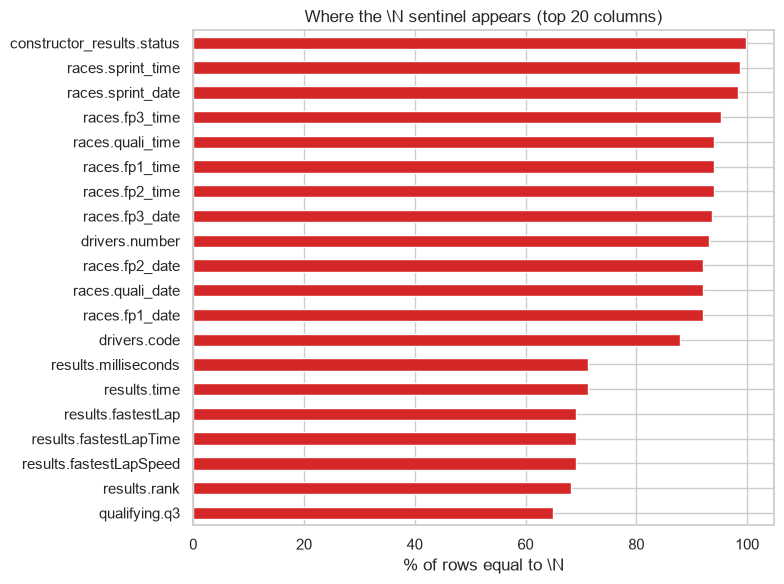

In [4]:
sentinel_columns = []
for name, table in raw.items():
    for col in table.columns:
        share = 100 * (table[col] == r"\N").mean()
        if share > 0:
            sentinel_columns.append({"column": f"{name}.{col}", "% of rows": share})
sentinel_columns = pd.DataFrame(sentinel_columns).sort_values("% of rows")
print(len(sentinel_columns), "of", sum(t.shape[1] for t in raw.values()), r"columns contain \N")

sentinel_columns.tail(20).plot.barh(x="column", y="% of rows", legend=False, color="tab:red", figsize=(8, 6))
plt.xlabel(r"% of rows equal to \N")
plt.ylabel("")
plt.title(r"Where the \N sentinel appears (top 20 columns)")
save("01_sentinel_columns")

`\N` is the dataset's placeholder for "no value". Before deciding what to do with it we check *where* it shows up. If it were random we could drop rows, but if it follows the history of the sport it carries information and has to be kept.

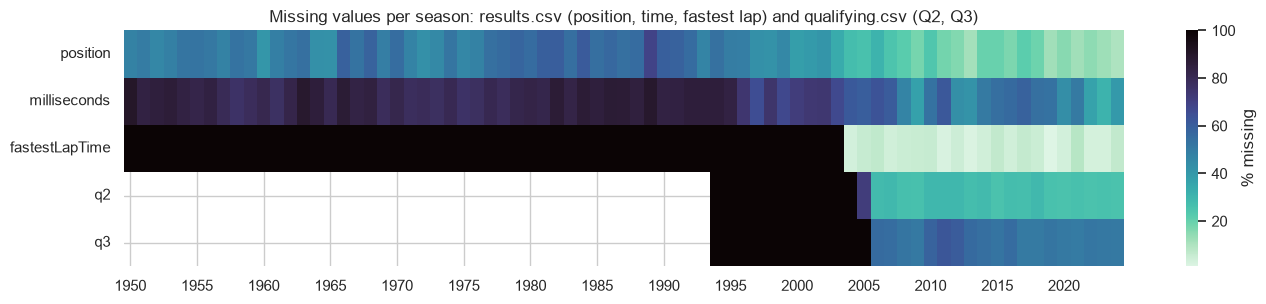

In [5]:
race_year = raw["races"][["raceId", "year"]].astype({"year": int})
race_year = race_year[race_year["year"] <= LAST_SEASON]   # newer dataset versions also contain 2025+
results_raw = raw["results"].merge(race_year, on="raceId")
quali_raw = raw["qualifying"].merge(race_year, on="raceId")

missing_by_season = pd.concat([
    results_raw.groupby("year")[["position", "milliseconds", "fastestLapTime"]].agg(lambda s: 100 * (s == r"\N").mean()),
    quali_raw.groupby("year")[["q2", "q3"]].agg(lambda s: 100 * s.isin([r"\N", ""]).mean()),
], axis=1)

plt.figure(figsize=(14, 3.2))
sns.heatmap(missing_by_season.T, cmap="mako_r", cbar_kws={"label": "% missing"}, xticklabels=5)
plt.xlabel("")
plt.title("Missing values per season: results.csv (position, time, fastest lap) and qualifying.csv (Q2, Q3)")
save("02_missing_by_season")

qualifying rows start in 1994; every race has them from 2003 on


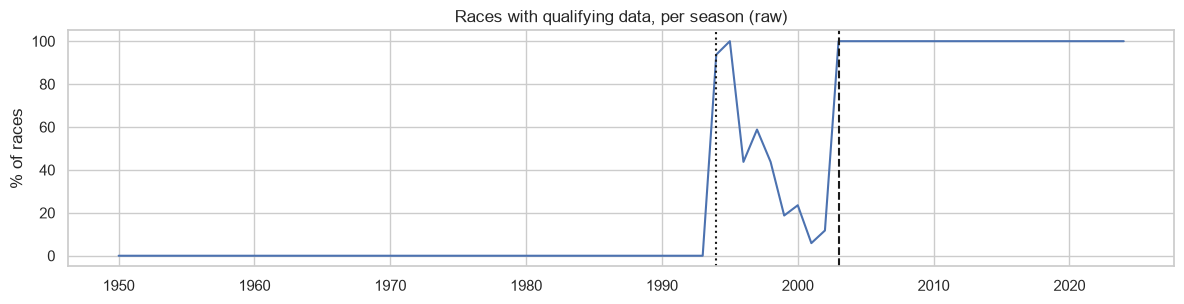

In [6]:
quali_coverage = 100 * quali_raw.groupby("year")["raceId"].nunique() / race_year.groupby("year").size()
quali_coverage = quali_coverage.fillna(0)
first_year = quali_coverage[quali_coverage > 0].index.min()
full_from = quali_coverage[quali_coverage < 99].index.max() + 1
print(f"qualifying rows start in {first_year}; every race has them from {full_from} on")

quali_coverage.plot(figsize=(12, 3.2))
plt.axvline(first_year, ls=":", color="k")
plt.axvline(full_from, ls="--", color="k")
plt.ylabel("% of races")
plt.xlabel("")
plt.title("Races with qualifying data, per season (raw)")
save("03_quali_coverage")

**What the plots tell us.** The missing values are structural, not random:

* `position` is `\N` whenever a driver was not classified, so it is really part of the outcome.
* Race times and fastest laps only exist for some cars and some eras.
* Q2 and Q3 only exist since the knockout format (2006); a driver knocked out in Q1 has no Q2/Q3 time by design.
* `qualifying.csv` only starts in 1994 and is complete for every race only from the season printed above. Before that, the only starting-order information is `grid` in `results.csv`.

So we will not drop rows because of missing qualifying data. Instead the model gets a `quali_missing` flag and median imputation with missing indicators (Section 9), and `grid` is always available as the fallback.

176 result rows share their (raceId, driverId) with another row (91 extra rows)
seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1962, 1964, 1978]


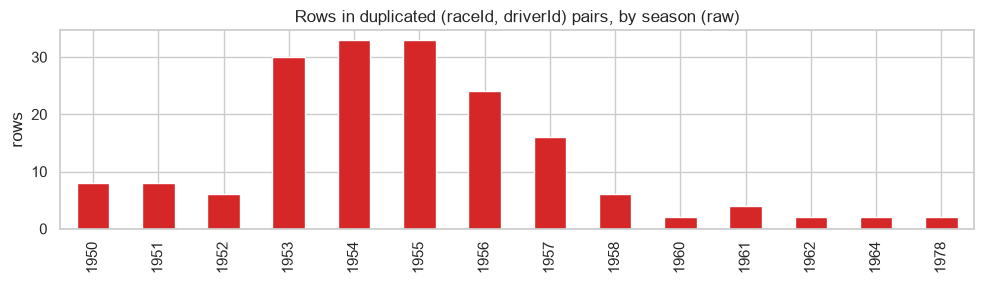

In [7]:
key = ["raceId", "driverId"]
dupes = results_raw[results_raw.duplicated(key, keep=False)]
print(f"{len(dupes)} result rows share their (raceId, driverId) with another row "
      f"({results_raw.duplicated(key).sum()} extra rows)")
print("seasons:", sorted(dupes["year"].unique().tolist()))

dupes.groupby("year").size().plot.bar(figsize=(10, 3), color="tab:red")
plt.ylabel("rows")
plt.xlabel("")
plt.title("Rows in duplicated (raceId, driverId) pairs, by season (raw)")
save("04_duplicates_by_season")

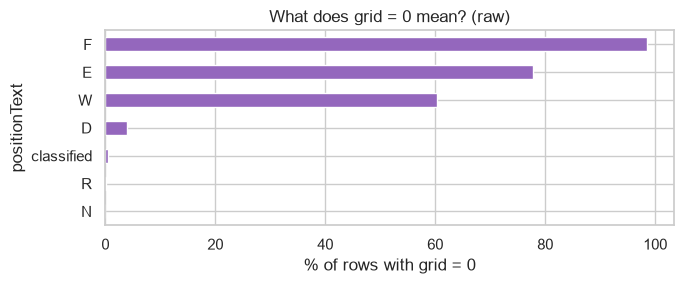

,rows,grid_0,% with grid 0
finish_code,,,
N,190,0,0.0
R,8897,14,0.2
classified,15808,60,0.4
D,151,6,4.0
W,336,203,60.4
E,9,7,77.8
F,1368,1348,98.5


In [8]:
# positionText codes: R retired, D disqualified, E excluded, W withdrawn, F failed to qualify, N not classified
results_raw["finish_code"] = results_raw["positionText"].where(~results_raw["positionText"].str.isdigit(), "classified")
grid_zero = results_raw.groupby("finish_code")["grid"].agg(rows="size", grid_0=lambda g: (g == "0").sum())
grid_zero["% with grid 0"] = (100 * grid_zero["grid_0"] / grid_zero["rows"]).round(1)
grid_zero = grid_zero.sort_values("% with grid 0")

grid_zero["% with grid 0"].plot.barh(figsize=(7, 3), color="tab:purple")
plt.xlabel("% of rows with grid = 0")
plt.ylabel("positionText")
plt.title("What does grid = 0 mean? (raw)")
save("05_grid_zero")
grid_zero

`grid = 0` is not one thing. For classified finishers it is rare (pit-lane starts), but almost every car that failed to qualify (`F`) and most withdrawn cars (`W`) also have `grid = 0`. Treating 0 as "pole position" would be wrong, so later we (a) drop the cars that never started, (b) add a `grid_zero` flag and (c) put the remaining grid-0 cars behind the field (`field_size + 1`).

### 2.1 Primary keys and foreign keys

A primary key must be unique and never null; every foreign key value must exist in the table it points to. `lap_times` and `pit_stops` have no id column, so we test their natural composite keys.

In [9]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "sprint_results": ["resultId"], "qualifying": ["qualifyId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}

# (child table, column, parent table). The parent's key column has the same name.
FOREIGN_KEYS = [("races", "year", "seasons"), ("races", "circuitId", "circuits")]
for child in ["results", "sprint_results", "qualifying", "lap_times", "pit_stops",
              "driver_standings", "constructor_standings", "constructor_results"]:
    for col, parent in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors"), ("statusId", "status")]:
        if col in raw[child].columns:
            FOREIGN_KEYS.append((child, col, parent))


def is_missing(values):
    return values.isna() | values.astype(str).isin([r"\N", ""])


def audit_keys(tables):
    pk = pd.DataFrame([{
        "table": table, "key": " + ".join(cols), "rows": len(tables[table]),
        "null keys": int(is_missing(tables[table][cols]).any(axis=1).sum()),
        "duplicate keys": int(tables[table].duplicated(cols).sum()),
    } for table, cols in PRIMARY_KEYS.items()])

    fk = []
    for child, col, parent in FOREIGN_KEYS:
        values = tables[child][col][~is_missing(tables[child][col])].astype(str)
        orphans = ~values.isin(set(tables[parent][col].astype(str)))
        fk.append({"foreign key": f"{child}.{col} -> {parent}", "rows checked": len(values), "orphans": int(orphans.sum())})
    return pk, pd.DataFrame(fk)


pk_raw, fk_raw = audit_keys(raw)
print("primary key problems:", int(pk_raw[["null keys", "duplicate keys"]].sum().sum()),
      "| foreign key orphans:", int(fk_raw["orphans"].sum()))
display(pk_raw)
fk_raw

primary key problems: 0 | foreign key orphans: 0


,table,key,rows,null keys,duplicate keys
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,seasons,year,75,0,0
5,status,statusId,139,0,0
6,results,resultId,26759,0,0
7,sprint_results,resultId,360,0,0
8,qualifying,qualifyId,10494,0,0
9,driver_standings,driverStandingsId,34863,0,0


,foreign key,rows checked,orphans
0,races.year -> seasons,1125,0
1,races.circuitId -> circuits,1125,0
2,results.raceId -> races,26759,0
3,results.driverId -> drivers,26759,0
4,results.constructorId -> constructors,26759,0
5,results.statusId -> status,26759,0
6,sprint_results.raceId -> races,360,0
7,sprint_results.driverId -> drivers,360,0
8,sprint_results.constructorId -> constructors,360,0
9,sprint_results.statusId -> status,360,0


Every primary key is unique and non-null, and every foreign key reconciles, so no rows have to be removed for referential integrity. The one real grain problem is analytical: `results` is unique on `resultId`, but **not** on `(raceId, driverId)`, which is the grain we need (shown above, handled in 3.3).

## 3. Cleaning (on copies)

### 3.1 Sentinels and semantic types

* `\N` and blank strings (qualifying has a few) become real missing values.
* Ids and counters become nullable integers (`Int64`), so a missing value doesn't turn an id into a float.
* `date`, `dob` and `*_date` become datetimes.
* Duration strings (`"1:27.452"`, `"1:02:03.5"`, `"26.898"`) get a numeric copy in seconds (`*_sec`). The original text column stays next to it.
* Text is stripped (the raw nationality list contains `"Argentinian "` with a trailing space).

`results.time` is left as text on purpose: for the winner it is the total race time, for everyone else it is a gap (`"+5.478"`). It is post-race information that we never use.

In [10]:
INT_COLS = {"year", "round", "number", "grid", "position", "positionOrder", "laps", "milliseconds",
            "fastestLap", "rank", "lap", "stop", "wins"}
FLOAT_COLS = {"points", "lat", "lng", "alt", "fastestLapSpeed"}
DURATION_COLS = {"qualifying": ["q1", "q2", "q3"], "lap_times": ["time"], "pit_stops": ["duration"],
                 "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"]}


def to_seconds(text):
    """'1:27.452' -> 87.452, '1:02:03.5' -> 3723.5, '26.898' -> 26.898"""
    if pd.isna(text):
        return np.nan
    seconds = 0.0
    for part in text.split(":"):
        seconds = seconds * 60 + float(part)
    return seconds


def clean_table(name, table):
    table = table.copy()
    for col in table.columns:
        values = table[col].str.strip()
        values = values.mask(values.isin([r"\N", ""]))
        if col.endswith("Id") or col in INT_COLS:
            table[col] = pd.to_numeric(values).astype("Int64")
        elif col in FLOAT_COLS:
            table[col] = pd.to_numeric(values)
        elif col in ("date", "dob") or col.endswith("_date"):
            table[col] = pd.to_datetime(values, format="%Y-%m-%d")
        else:
            table[col] = values
        if col in DURATION_COLS.get(name, []):
            table[col + "_sec"] = values.map(to_seconds)
    return table


clean = {name: clean_table(name, table) for name, table in raw.items()}

assert all(len(clean[name]) == len(raw[name]) for name in raw)     # typing never drops rows
assert (raw["results"]["position"] == r"\N").any()                 # the raw copy still has its sentinels
pd.DataFrame({"raw dtype": raw["results"].dtypes.astype(str),
              "clean dtype": clean["results"].dtypes.astype(str),
              "missing after cleaning": clean["results"].isna().sum()})

,raw dtype,clean dtype,missing after cleaning
constructorId,str,Int64,0
driverId,str,Int64,0
fastestLap,str,Int64,18507
fastestLapSpeed,str,float64,18507
fastestLapTime,str,str,18507
fastestLapTime_sec,NaN,float64,18507
grid,str,Int64,0
laps,str,Int64,0
milliseconds,str,Int64,19079
number,str,Int64,6


In [11]:
# the parsed durations must agree with the separate milliseconds columns
laps, stops = clean["lap_times"], clean["pit_stops"]
pd.Series({
    "lap_times.time vs milliseconds": (laps["time_sec"] * 1000 - laps["milliseconds"]).abs().max(),
    "pit_stops.duration vs milliseconds": (stops["duration_sec"] * 1000 - stops["milliseconds"]).abs().max(),
}, name="largest difference (ms)")

lap_times.time vs milliseconds        1.164153e-10
pit_stops.duration vs milliseconds    2.328306e-10
Name: largest difference (ms), dtype: float64

In [12]:
pk_clean, fk_clean = audit_keys(clean)
print("after cleaning -> primary key problems:", int(pk_clean[["null keys", "duplicate keys"]].sum().sum()),
      "| foreign key orphans:", int(fk_clean["orphans"].sum()))

after cleaning -> primary key problems: 0 | foreign key orphans: 0


### 3.2 Who counts as "a driver entering a race"?

* **Seasons up to 2024**, to match the milestone (newer versions of the dataset also include 2025+).
* **No Indianapolis 500 (1950-1960).** It counted for the championship but was run by a separate field of American oval specialists, with its own grid structure. Keeping it would add 11 races where almost none of the F1 regulars started, and it would inflate "home race" counts for American drivers in Q2.
* **No cars that failed to qualify** (`positionText = 'F'`: DNQ, DNPQ, 107% rule). They were eliminated before our prediction cutoff and never took the start, so there is nothing to predict for them.

In [13]:
races = clean["races"].rename(columns={"name": "race_name"})
results = (clean["results"]
           .merge(races[["raceId", "year", "round", "date", "circuitId", "race_name"]], on="raceId")
           .merge(clean["status"], on="statusId"))
row_counts = {"raw results": len(results)}

results = results[results["year"] <= LAST_SEASON]
row_counts[f"seasons up to {LAST_SEASON}"] = len(results)

results = results[results["race_name"] != "Indianapolis 500"]
row_counts["without the Indy 500"] = len(results)

# positionText F = failed to qualify (DNQ, DNPQ, 107% rule): these cars never took the start
print(results.loc[results["positionText"] == "F", "status"].value_counts().to_dict())
results = results[results["positionText"] != "F"]
row_counts["without non-qualifiers"] = len(results)
pd.Series(row_counts)

{'Did not qualify': 1025, 'Did not prequalify': 331, '107% Rule': 9, 'Injury': 3}


raw results               26759
seasons up to 2024        26759
without the Indy 500      26354
without non-qualifiers    24986
dtype: int64

### 3.3 One row per `(raceId, driverId)`

The remaining duplicates are shared drives from the 1950s and early 1960s, when a driver could hand their car to a team-mate or take over another car mid-race. Let's look at a few before choosing a rule.

In [14]:
dupes = results[results.duplicated(key, keep=False)].sort_values(key + ["resultId"])
print(len(dupes.drop_duplicates(key)), "duplicated (raceId, driverId) pairs remain,", len(dupes), "rows")
dupes[["resultId", "raceId", "year", "driverId", "constructorId", "grid", "positionText", "positionOrder", "status"]].head(8)

62 duplicated (raceId, driverId) pairs remain, 127 rows


,resultId,raceId,year,driverId,constructorId,grid,positionText,positionOrder,status
17362,17363,717,1964,373,172,1,7,7,Out of fuel
24298,24304,717,1964,373,172,1,R,12,Injection
17740,17741,733,1962,465,172,0,W,22,Withdrew
17743,17744,733,1962,465,97,0,W,25,Withdrew
17961,17962,742,1961,475,102,20,D,19,Disqualified
17963,17964,742,1961,475,172,5,R,21,Brakes
18062,18063,745,1961,418,172,11,R,17,Gearbox
24297,24303,745,1961,418,172,15,11,11,+8 Laps


**Rule we use:**

1. Keep the entry where the driver actually held a grid slot (`grid > 0`): that is the car the driver started the race in, which is what a pre-race prediction is about.
2. If that still leaves a tie, keep the lowest `resultId` (the original entry; relief-drive rows were added later with higher ids).

We deliberately do **not** keep "the best finishing position". That would use the label to pick the row and would push the podium rate up, which is a quiet form of leakage. Below we count how many labels that alternative would have changed, so the effect of our choice is visible.

In [15]:
results = results.assign(started=results["grid"] > 0)
by_start = (results.sort_values(key + ["started", "resultId"], ascending=[True, True, False, True])
            .drop_duplicates(key))
by_best_finish = results.sort_values(key + ["positionOrder", "resultId"]).drop_duplicates(key)

compare = by_start.merge(by_best_finish, on=key, suffixes=("", "_alt"))
changed = ((compare["positionOrder"] <= 3) != (compare["positionOrder_alt"] <= 3)).sum()
print(f"removed {len(results) - len(by_start)} duplicate rows; "
      f"the 'best finish' rule would have changed {changed} podium labels")

results = by_start.drop(columns="started")
row_counts["one row per (raceId, driverId)"] = len(results)
assert not results.duplicated(key).any()

removed 65 duplicate rows; the 'best finish' rule would have changed 15 podium labels


### 3.4 The analytical base table

`results` (scoped, deduplicated) -> `races` (season, round, circuit) -> `circuits` (country) -> `drivers` (nationality) -> `constructors` (team name) -> `status` (why a car stopped, used for Q3 only) -> `qualifying` (left join, because qualifying only exists from 1994). After the joins we check again that there is still exactly one row per driver per race.

24,921 rows, 1,114 races, podium rate 13.4%, qualifying available for 42.1% of rows

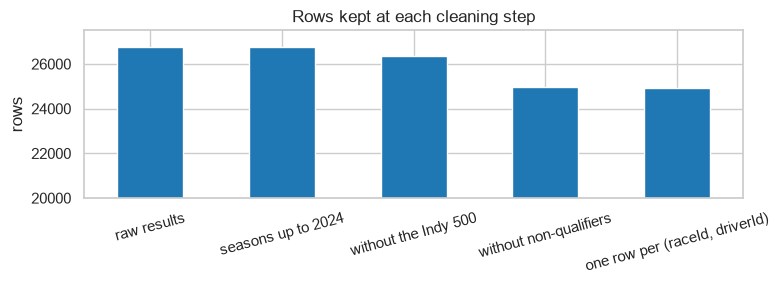

In [16]:
drivers = clean["drivers"][["driverId", "forename", "surname", "nationality", "dob"]]
constructors = clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"})
circuits = clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit", "country": "circuit_country"})
quali = (clean["qualifying"][["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]]
         .rename(columns={"position": "quali_position"}))

base = (results
        .merge(drivers, on="driverId", how="left")
        .merge(constructors, on="constructorId", how="left")
        .merge(circuits, on="circuitId", how="left")
        .merge(quali, on=key, how="left"))
assert len(base) == len(results) and not base.duplicated(key).any()   # the joins kept the grain

base = base.astype({"year": int, "round": int, "grid": float, "positionOrder": float, "quali_position": float})
base["podium"] = (base["positionOrder"] <= 3).astype(int)
base["field_size"] = base.groupby("raceId")["driverId"].transform("size")

print(f"{len(base):,} rows, {base['raceId'].nunique():,} races, podium rate {base['podium'].mean():.1%}, "
      f"qualifying available for {base['quali_position'].notna().mean():.1%} of rows")

pd.Series(row_counts).plot.bar(figsize=(8, 3), color="tab:blue", rot=15)
plt.ylim(20000, 27500)
plt.ylabel("rows")
plt.title("Rows kept at each cleaning step")
save("06_row_counts")

## 4. EDA after cleaning

Same questions as Section 2, now on the cleaned, deduplicated table: what did the cleaning change, and what do the newly typed columns look like?

overall podium rate: raw 12.69% -> clean 13.42%


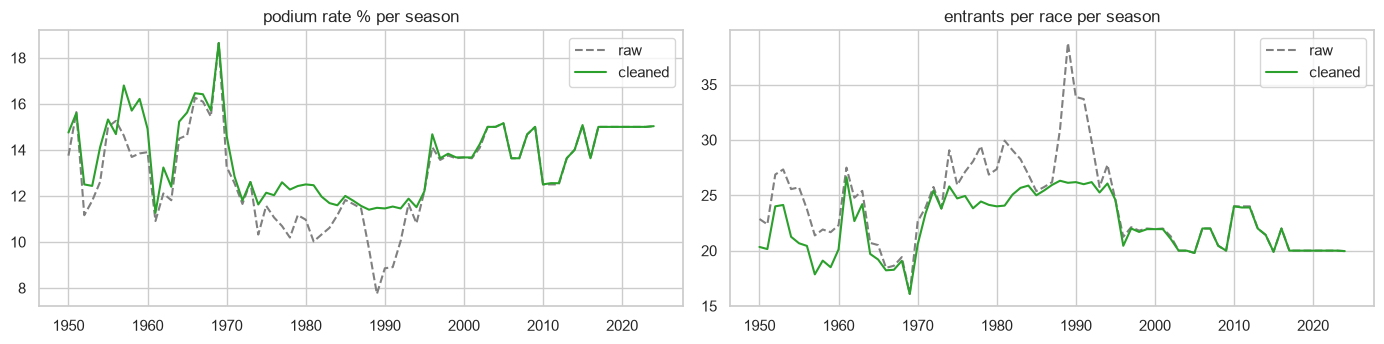

In [17]:
def per_season(table, podium):
    grouped = table.assign(podium=podium).groupby("year")
    return pd.DataFrame({"podium rate %": 100 * grouped["podium"].mean(),
                         "entrants per race": grouped.size() / grouped["raceId"].nunique()})


before = per_season(results_raw, results_raw["positionOrder"].astype(int) <= 3)
after = per_season(base, base["podium"])
print(f"overall podium rate: raw {results_raw['positionOrder'].astype(int).le(3).mean():.2%} -> clean {base['podium'].mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, col in zip(axes, before.columns):
    ax.plot(before.index, before[col], "--", color="grey", label="raw")
    ax.plot(after.index, after[col], color="tab:green", label="cleaned")
    ax.set_title(col + " per season")
    ax.legend()
save("07_before_after_cleaning")

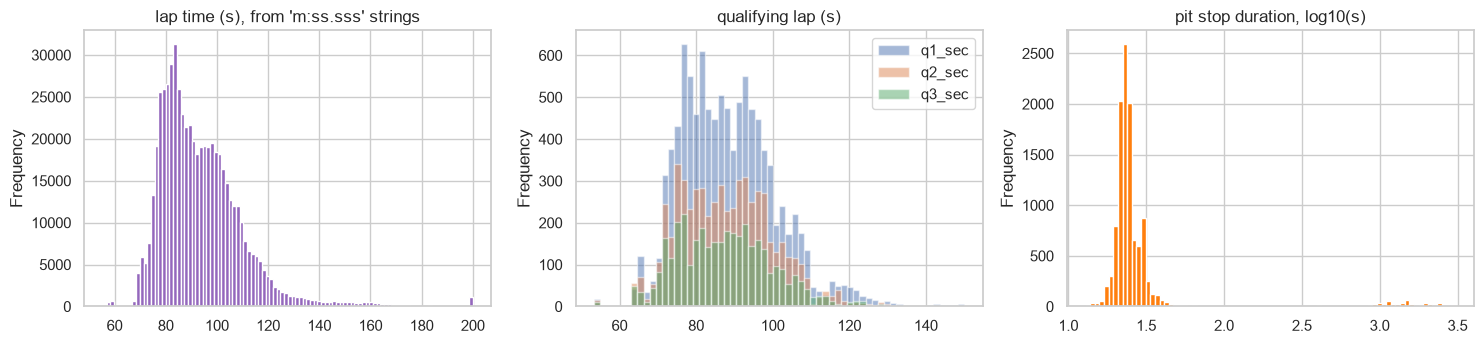

grid               0.0
quali_position    57.9
q1_sec            58.5
q2_sec            76.5
q3_sec            85.4
position          37.7
milliseconds      69.7
Name: % missing, dtype: float64

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
clean["lap_times"]["time_sec"].clip(upper=200).plot.hist(bins=100, ax=axes[0], color="tab:purple")
axes[0].set_title("lap time (s), from 'm:ss.sss' strings")
clean["qualifying"][["q1_sec", "q2_sec", "q3_sec"]].clip(upper=150).plot.hist(bins=60, alpha=0.5, ax=axes[1])
axes[1].set_title("qualifying lap (s)")
np.log10(clean["pit_stops"]["duration_sec"]).plot.hist(bins=80, ax=axes[2], color="tab:orange")
axes[2].set_title("pit stop duration, log10(s)")
save("08_cleaned_distributions")

base[["grid", "quali_position", "q1_sec", "q2_sec", "q3_sec", "position", "milliseconds"]].isna().mean().mul(100).round(1).rename("% missing")

**Effect of cleaning.**

* Removing the Indy 500 and the non-qualifiers mainly changes the 1950s-1990s: the "entrants per race" curve drops in the late 1980s, when 30+ cars entered but only 26 could start. The podium rate per season goes up accordingly, because three podium places are now shared among the cars that actually started.
* The typed columns look sensible: lap times cluster around 70-120 s, qualifying laps around 60-120 s, and pit-stop durations have a long right tail (red flags, penalties), which is one more reason we don't use them.
* `position` and `milliseconds` are mostly missing, but they are outcomes and are never used as features. `quali_position` is missing for about 58% of rows, which matches the coverage plot in Section 2.

## 5. Data-engineering questions

### Q1. Which circuits convert a front-row start into a podium most often, and does that ranking change after 2014?

* **Front row by qualifying:** `qualifying.position` is 1 or 2 (what the lap time earned).
* **Front row by grid:** `results.grid` is 1 or 2 (where the car actually started, after penalties).
* **Conversion rate:** podiums / front-row starts, per circuit and era (pre-2014 vs the hybrid era 2014+).

**Join path:** `results -> races -> circuits` plus `results -> qualifying` on `(raceId, driverId)`.
**Grain:** one row per driver per race. **Missingness:** qualifying only exists from 1994, so both definitions are computed on the same rows (races with qualifying data). A circuit is only ranked if it has at least 12 front-row starts in *each* era. **Cutoff:** both qualifying position and grid are known before the start; the podium is the outcome.

In [19]:
q1 = base[base["quali_position"].notna()].copy()     # races with qualifying data (1994 onwards)
q1["era"] = np.where(q1["year"] >= 2014, "2014+", "pre-2014")
q1["front_row_quali"] = q1["quali_position"] <= 2
q1["front_row_grid"] = q1["grid"].isin([1, 2])
MIN_STARTS = 12   # front-row starts per circuit and era, so a single weekend can't decide the ranking


def conversion_by_circuit(flag):
    front_row = q1[q1[flag]]
    table = front_row.pivot_table(index="circuit", columns="era", values="podium", aggfunc=["mean", "size"])
    table = table[(table["size"] >= MIN_STARTS).all(axis=1)]
    out = table["mean"].copy()
    out["starts pre-2014"], out["starts 2014+"] = table["size"]["pre-2014"], table["size"]["2014+"]
    out["rank pre-2014"] = out["pre-2014"].rank(ascending=False, method="min").astype(int)
    out["rank 2014+"] = out["2014+"].rank(ascending=False, method="min").astype(int)
    return out.sort_values("2014+", ascending=False)


by_quali = conversion_by_circuit("front_row_quali")
by_grid = conversion_by_circuit("front_row_grid")
for name, table in [("qualifying", by_quali), ("grid", by_grid)]:
    rho, p = stats.spearmanr(table["pre-2014"], table["2014+"])
    print(f"front row by {name}: {len(table)} circuits, rank correlation between eras rho = {rho:.2f} (p = {p:.2f})")

overall = pd.DataFrame({"front row by qualifying": q1[q1["front_row_quali"]].groupby("era")["podium"].mean(),
                        "front row by grid": q1[q1["front_row_grid"]].groupby("era")["podium"].mean()})
display(overall.round(3))
by_quali.round(3)

front row by qualifying: 13 circuits, rank correlation between eras rho = 0.22 (p = 0.48)
front row by grid: 13 circuits, rank correlation between eras rho = 0.23 (p = 0.45)


,front row by qualifying,front row by grid
era,,
2014+,0.737,0.760
pre-2014,0.647,0.652


era,2014+,pre-2014,starts pre-2014,starts 2014+,rank pre-2014,rank 2014+
circuit,,,,,,
Suzuka Circuit,0.889,0.769,26.0,18.0,1,1
Circuit de Monaco,0.850,0.643,28.0,20.0,7,2
Circuit de Spa-Francorchamps,0.818,0.542,24.0,22.0,12,3
Circuit de Barcelona-Catalunya,0.818,0.633,30.0,22.0,8,3
Shanghai International Circuit,0.786,0.700,20.0,14.0,2,5
Silverstone Circuit,0.750,0.656,32.0,24.0,4,6
Autodromo Nazionale di Monza,0.727,0.654,26.0,22.0,5,7
Circuit Gilles Villeneuve,0.722,0.577,26.0,18.0,11,8
Albert Park Grand Prix Circuit,0.722,0.531,32.0,18.0,13,8


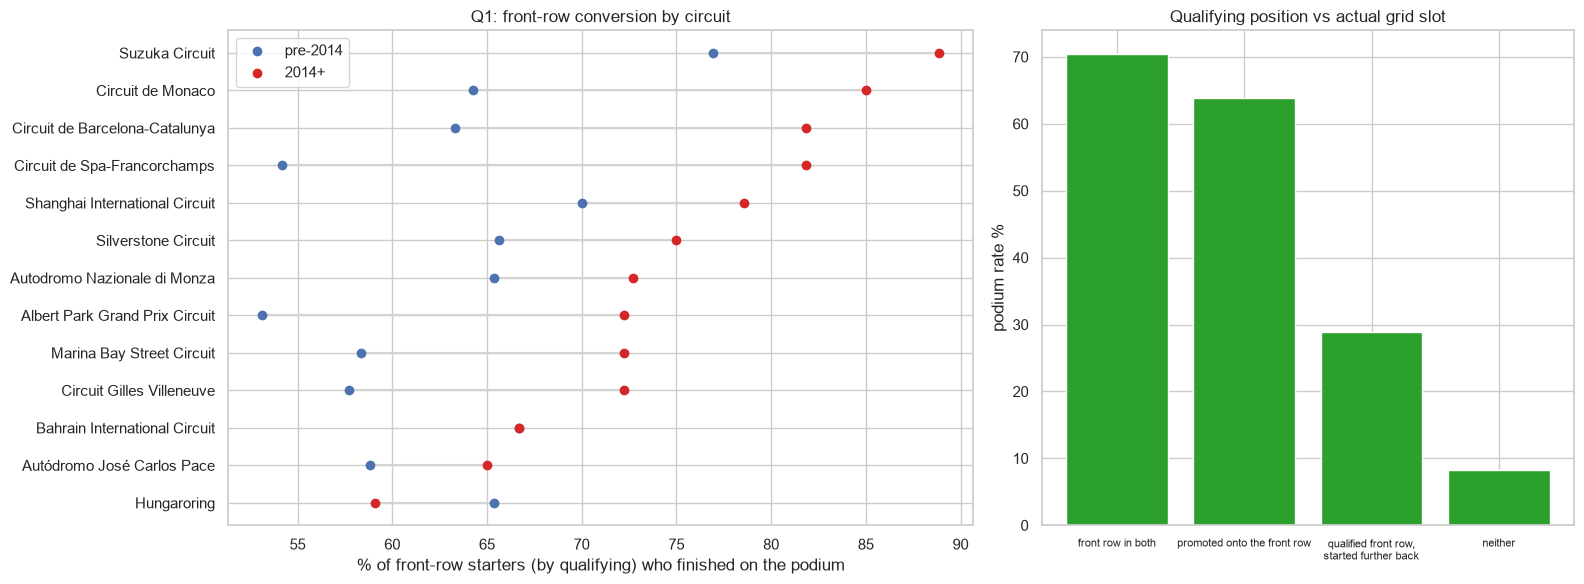

,rows,podium_rate
front row in both,950,0.704
promoted onto the front row,36,0.639
"qualified front row, started further back",38,0.289
neither,9462,0.082


In [20]:
group = np.select(
    [q1["front_row_quali"] & q1["front_row_grid"], q1["front_row_quali"] & ~q1["front_row_grid"], ~q1["front_row_quali"] & q1["front_row_grid"]],
    ["front row in both", "qualified front row, started further back", "promoted onto the front row"], "neither")
quali_vs_grid = q1.groupby(group)["podium"].agg(rows="size", podium_rate="mean").sort_values("podium_rate", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})
plot = by_quali.sort_values("2014+")
axes[0].hlines(plot.index, 100 * plot["pre-2014"], 100 * plot["2014+"], color="lightgrey")
axes[0].scatter(100 * plot["pre-2014"], plot.index, label="pre-2014", zorder=3)
axes[0].scatter(100 * plot["2014+"], plot.index, label="2014+", color="tab:red", zorder=3)
axes[0].set_xlabel("% of front-row starters (by qualifying) who finished on the podium")
axes[0].set_title("Q1: front-row conversion by circuit")
axes[0].legend()
axes[1].bar(quali_vs_grid.index.str.replace(", ", ",\n"), 100 * quali_vs_grid["podium_rate"], color="tab:green")
axes[1].set_ylabel("podium rate %")
axes[1].set_title("Qualifying position vs actual grid slot")
axes[1].tick_params(axis="x", labelsize=8)
save("09_q1_front_row_conversion")
quali_vs_grid.round(3)

**Q1 answer.**

* **Best converters.** Since 2014 a front-row qualifier finished on the podium most often at **Suzuka (89%)**, **Monaco (85%)**, and **Spa and Barcelona (82% each)**. Before 2014 the top three were Suzuka (77%), Shanghai (70%) and Bahrain (67%).
* **Converting got easier overall.** Front-row qualifiers made the podium 65% of the time before 2014 and 74% from 2014 (by grid: 65% -> 76%). 11 of the 13 ranked circuits convert more often in the hybrid era; Bahrain stays level and the Hungaroring is the only one that drops (65% -> 59%).
* **Yes, the ranking changes a lot.** The rank correlation between the two eras is only rho = 0.22 (p = 0.48) using qualifying and 0.23 (p = 0.45) using the grid, which is statistically indistinguishable from "no relationship". Suzuka is first in both eras, but Spa jumps from #12 to #3, Barcelona from #8 to #3 and Monaco from #7 to #2, while Bahrain falls from #3 to #11 and the Hungaroring from #5 to #13.
* **Qualifying is not the same as the grid.** Drivers who qualified on the front row *and* started there reached the podium 70% of the time (n = 950). Those who qualified on the front row but started further back because of a penalty or a pit-lane start made it only 29% of the time (n = 38), while drivers promoted onto the front row by other people's penalties converted 64% (n = 36). Where the car actually starts matters more than the lap time that earned the slot.
* **Caveats.** Only 13 circuits have enough front-row starts in both eras, each with 6-17 races per era. Track layouts changed, and the post-2014 era was dominated by one or two teams, so circuit effects and team dominance are mixed together.

### Q2. Do drivers podium more often at home, after controlling for starting position?

**Join path:** `results -> drivers.nationality` and `results -> races -> circuits.country`. "Home" means the circuit is in the driver's country. The mapping below is written out by hand; dual nationalities map to both countries, and nationalities with no Grand Prix (Finnish, Danish, ...) can never be at home.

**Controlling for starting position:** we only compare drivers who started from similar grid slots. First with a Mantel-Haenszel odds ratio (one 2x2 table per grid bucket, pooled), then with a logistic regression that adds era effects and clusters the errors by driver (the same driver appears many times).

**Grain:** driver-race. **Missingness:** none in `grid` or nationality; rows with `grid = 0` are left out because they have no comparable starting slot. **Cutoff:** home status and grid are both known before the start.

In [21]:
NATIONALITY_TO_COUNTRY = {
    "British": ["UK"], "American": ["USA", "United States"], "American-Italian": ["USA", "United States", "Italy"],
    "Argentine": ["Argentina"], "Argentinian": ["Argentina"], "Argentine-Italian": ["Argentina", "Italy"],
    "Australian": ["Australia"], "Austrian": ["Austria"], "Belgian": ["Belgium"], "Brazilian": ["Brazil"],
    "Canadian": ["Canada"], "Chinese": ["China"], "Dutch": ["Netherlands"], "French": ["France"],
    "German": ["Germany"], "East German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"],
    "Italian": ["Italy"], "Japanese": ["Japan"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"],
    "Monegasque": ["Monaco"], "Portuguese": ["Portugal"], "Russian": ["Russia"], "South African": ["South Africa"],
    "Spanish": ["Spain"], "Swedish": ["Sweden"], "Swiss": ["Switzerland"],
}
print("nationalities without a home race:", sorted(set(base["nationality"]) - set(NATIONALITY_TO_COUNTRY)))

base["is_home"] = [int(country in NATIONALITY_TO_COUNTRY.get(nat, [])) for nat, country in zip(base["nationality"], base["circuit_country"])]

q2 = base[base["grid"] > 0].copy()      # grid 0 has no comparable starting slot
q2["grid_bucket"] = pd.cut(q2["grid"], [0, 1, 2, 3, 5, 8, 12, 20, 40],
                           labels=["P1", "P2", "P3", "P4-5", "P6-8", "P9-12", "P13-20", "P21+"])
q2["era"] = pd.cut(q2["year"], [1949, 1979, 1993, 2013, 2024], labels=["1950-79", "1980-93", "1994-2013", "2014-24"])

naive = q2.groupby("is_home")["podium"].agg(starts="size", podium_rate="mean").rename(index={0: "away", 1: "home"})
by_bucket = q2.pivot_table(index="grid_bucket", columns="is_home", values="podium", aggfunc=["mean", "size"], observed=True)
display(naive.round(4))
by_bucket.round(3)

nationalities without a home race: ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']


,starts,podium_rate
is_home,,
away,22691,0.1375
home,1941,0.1159


mean         size     
is_home          0      1     0    1
grid_bucket                         
P1           0.644  0.598  1034   82
P2           0.561  0.538  1033   78
P3           0.457  0.535  1044   71
P4-5         0.294  0.345  2089  145
P6-8         0.139  0.110  3101  237
P9-12        0.054  0.049  4107  346
P13-20       0.015  0.004  7799  689
P21+         0.005  0.000  2484  293

Mantel-Haenszel odds ratio, home vs away within the same grid bucket: 0.93 (95% CI 0.78-1.11, p = 0.43)


logistic regression odds ratio for is_home: 0.93 (95% CI 0.76-1.14, p = 0.50)


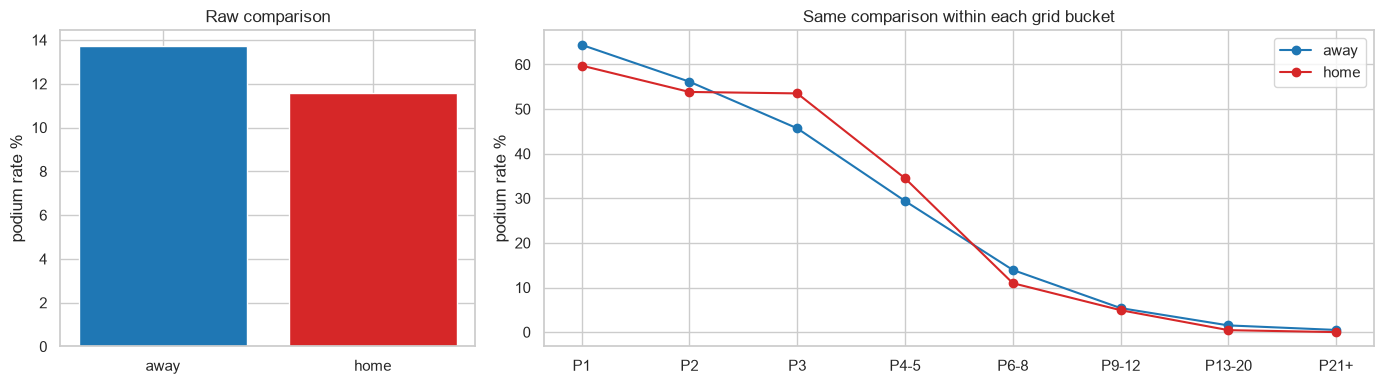

In [22]:
# 1) Mantel-Haenszel: one 2x2 table (home/away x podium/no podium) per grid bucket, pooled
tables = [pd.crosstab(g["is_home"], g["podium"]).reindex(index=[1, 0], columns=[1, 0], fill_value=0).values
          for _, g in q2.groupby("grid_bucket", observed=True)]
mh = StratifiedTable(tables)
low, high = mh.oddsratio_pooled_confint()
print(f"Mantel-Haenszel odds ratio, home vs away within the same grid bucket: {mh.oddsratio_pooled:.2f} "
      f"(95% CI {low:.2f}-{high:.2f}, p = {mh.test_null_odds().pvalue:.2f})")

# 2) logistic regression with grid-bucket and era effects, errors clustered by driver
logit = smf.logit("podium ~ is_home + C(grid_bucket) + C(era)", data=q2).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": q2["driverId"].astype(int)})
low, high = np.exp(logit.conf_int().loc["is_home"])
print(f"logistic regression odds ratio for is_home: {np.exp(logit.params['is_home']):.2f} "
      f"(95% CI {low:.2f}-{high:.2f}, p = {logit.pvalues['is_home']:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(naive.index, 100 * naive["podium_rate"], color=["tab:blue", "tab:red"])
axes[0].set_ylabel("podium rate %")
axes[0].set_title("Raw comparison")
for is_home, label, color in [(0, "away", "tab:blue"), (1, "home", "tab:red")]:
    axes[1].plot(by_bucket.index.astype(str), 100 * by_bucket[("mean", is_home)], marker="o", color=color, label=label)
axes[1].set_ylabel("podium rate %")
axes[1].set_title("Same comparison within each grid bucket")
axes[1].legend()
save("10_q2_home_advantage")

**Q2 answer: no. Once we compare drivers who started from similar grid slots, there is no evidence that they podium more often at home.**

* **The raw numbers point the other way.** Home starters reached the podium 11.6% of the time against 13.7% away (1,941 home starts). That is mostly about *where* home drivers start: 15% of home starts are from P21 or lower, against 11% of away starts.
* **Within the same grid bucket the two curves lie on top of each other** (right panel). The pooled Mantel-Haenszel odds ratio is **0.93** (95% CI 0.78-1.11, p = 0.43), and the logistic regression with grid bucket and era gives **0.93** (95% CI 0.76-1.14, p = 0.50). Both intervals include 1.
* **What we can and cannot say.** A large home advantage is ruled out (the upper limits are +11% and +14% in odds), a small one is not. This is observational: driver quality is not fully captured by the grid slot, and the home sample is dominated by British, Italian, French and German drivers.

### Q3. Which constructors have the highest mechanical-retirement rate in 2014-2021 vs 2022-2024?

**Definition.** A mechanical retirement is a race start that ended because a component failed. We list those `status` values explicitly below (engine, gearbox, hydraulics, power unit, ERS, brakes, suspension, ...). Not counted:

* crashes and driver errors (`Accident`, `Collision`, `Spun off`, `Collision damage`),
* regulation decisions (`Disqualified`, `Excluded`, `Underweight`),
* statuses that could be either contact or failure (`Puncture`, `Wheel`, `Front wing`, `Damage`, `Debris`, and the generic `Retired`).

**Denominator:** race starts, so cars that withdrew or did not qualify are excluded. **Join path:** `results -> status`, `results -> constructors`, `results -> races`. **Grain:** one start of one car. **Cutoff:** not applicable, `status` is post-race information and is only used to describe history here, never as a model feature.

The printout under the first cell lists every retirement reason that we did *not* count, so the mapping can be checked by eye.

In [23]:
MECHANICAL = [
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Electronics", "Radiator",
    "Suspension", "Brakes", "Brake duct", "Differential", "Overheating", "Mechanical", "Technical", "Driveshaft",
    "Halfshaft", "Drivetrain", "CV joint", "Axle", "Wheel bearing", "Track rod", "Steering", "Throttle",
    "Fuel pressure", "Fuel pump", "Fuel system", "Fuel leak", "Fuel pipe", "Fuel", "Injection", "Ignition",
    "Oil pressure", "Oil leak", "Oil line", "Oil pipe", "Oil pump", "Water pressure", "Water leak", "Water pipe",
    "Water pump", "Cooling system", "Exhaust", "Turbo", "Supercharger", "Power Unit", "ERS", "Battery",
    "Alternator", "Power loss", "Engine fire", "Engine misfire", "Heat shield fire", "Fire", "Pneumatics",
    "Launch control", "Vibrations", "Chassis", "Crankshaft", "Spark plugs", "Distributor", "Magneto",
]
NOT_STARTED = ["Withdrew", "Did not qualify", "Did not prequalify", "107% Rule"]

q3 = base[(base["year"] >= 2014) & ~base["status"].isin(NOT_STARTED)].copy()
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
q3["mechanical"] = q3["status"].isin(MECHANICAL).astype(int)

finished = (q3["status"] == "Finished") | q3["status"].str.startswith("+")
print("retirements we did NOT count as mechanical:")
print(q3.loc[~finished & (q3["mechanical"] == 0), "status"].value_counts().to_dict())
q3.groupby("period")["mechanical"].agg(starts="size", mechanical_dnfs="sum", rate="mean").round(4)

retirements we did NOT count as mechanical:
{'Collision': 150, 'Accident': 85, 'Collision damage': 59, 'Retired': 50, 'Disqualified': 11, 'Wheel': 11, 'Spun off': 11, 'Puncture': 7, 'Tyre': 4, 'Undertray': 4, 'Rear wing': 3, 'Front wing': 3, 'Wheel nut': 3, 'Illness': 3, 'Damage': 2, 'Excluded': 1, 'Seat': 1, 'Out of fuel': 1, 'Debris': 1}


,starts,mechanical_dnfs,rate
period,,,
2014-2021,3258,300,0.0921
2022-2024,1354,77,0.0569


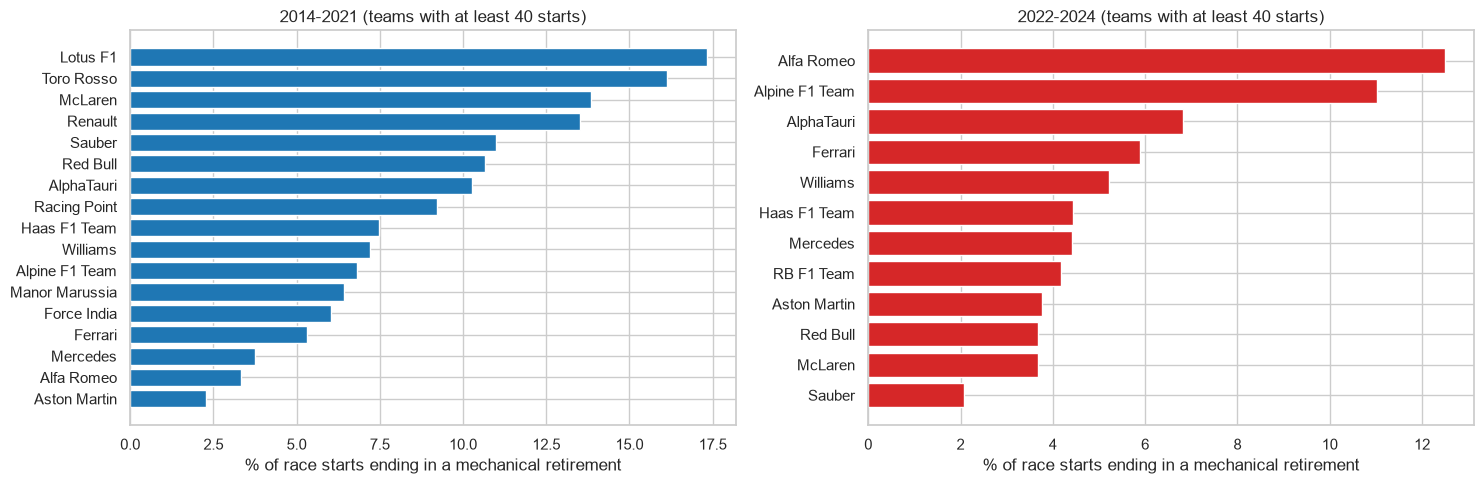

2014-2021


,period,constructor,starts,mechanical_dnfs,rate
8,2014-2021,Lotus F1,75,13,0.173
17,2014-2021,Toro Rosso,242,39,0.161
11,2014-2021,McLaren,318,44,0.138
15,2014-2021,Renault,200,27,0.135
16,2014-2021,Sauber,200,22,0.110


2022-2024


,period,constructor,starts,mechanical_dnfs,rate
19,2022-2024,Alfa Romeo,88,11,0.125
21,2022-2024,Alpine F1 Team,136,15,0.110
20,2022-2024,AlphaTauri,88,6,0.068
23,2022-2024,Ferrari,136,8,0.059
30,2022-2024,Williams,134,7,0.052


In [24]:
MIN_TEAM_STARTS = 40
rates = (q3.groupby(["period", "constructor"])["mechanical"]
         .agg(starts="size", mechanical_dnfs="sum", rate="mean").reset_index())
rates = rates[rates["starts"] >= MIN_TEAM_STARTS]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (period, color) in zip(axes, [("2014-2021", "tab:blue"), ("2022-2024", "tab:red")]):
    part = rates[rates["period"] == period].sort_values("rate")
    ax.barh(part["constructor"], 100 * part["rate"], color=color)
    ax.set_xlabel("% of race starts ending in a mechanical retirement")
    ax.set_title(f"{period} (teams with at least {MIN_TEAM_STARTS} starts)")
save("11_q3_mechanical_retirements")

for period in ["2014-2021", "2022-2024"]:
    print(period)
    display(rates[rates["period"] == period].sort_values("rate", ascending=False).head(5).round(3))

**Q3 answer.**

* **2014-2021** (3,258 starts, 9.2% of all starts ended in a mechanical retirement): the highest rates belong to **Lotus F1 (17.3%, 13 of 75)**, **Toro Rosso (16.1%, 39 of 242)**, **McLaren (13.8%, 44 of 318)**, Renault (13.5%) and Sauber (11.0%). Caterham was even higher (8 of 34) but has fewer than 40 starts, so it is not ranked.
* **2022-2024** (1,354 starts, 5.7%): **Alfa Romeo (12.5%, 11 of 88)** and **Alpine (11.0%, 15 of 136)** are clearly ahead of everyone else; next come AlphaTauri (6.8%), Ferrari (5.9%) and Williams (5.2%).
* **Reliability improved across the grid**, by 3.5 percentage points overall. The biggest improvements are at McLaren (13.8% -> 3.7%) and Red Bull (10.7% -> 3.7%). The Renault/Alpine works team is near the top in both periods (13.5% -> 11.0%).
* **Caveats.** In 2022-2024 a team has only 88-136 starts, so one or two failures move its rate by 1-2 points. Team renames (Toro Rosso -> AlphaTauri -> RB, Sauber -> Alfa Romeo -> Sauber, Renault -> Alpine) are kept under the name used in the dataset. 50 retirements are only recorded as "Retired" and could hide more mechanical failures.

## 6. Leakage-safe feature engineering

**Cutoff:** after qualifying, before the race. A feature is allowed only if it comes from

1. the qualifying session or the starting grid of *this* race, or
2. results and standings of **strictly earlier** races.

| Source | Allowed? |
|---|---|
| this race's `positionOrder`, `position`, `points`, `laps`, `time`, `fastestLap`, `rank`, `status` | no, these are the outcome |
| `lap_times`, `pit_stops` of this race | no, they happen during the race |
| `driver_standings` / `constructor_standings` of this race | no, they already include this race; we use the standing after the previous round instead |
| `sprint_results` | left out: only ~20 weekends since 2021, and the sprint result is already reflected in the grid |
| qualifying and `grid` of this race | yes |
| earlier races (form, standings, history at the circuit) | yes |

Races are put in chronological order with `(year, round)`. All "form" features are computed with `shift(1)`, so the current race is never included. We build a few more candidates than we need and choose between them in Section 8.

In [25]:
df = base.sort_values(["year", "round", "driverId"]).reset_index(drop=True)
df["race_order"] = df["year"] * 100 + df["round"]       # chronological race number

# post-race helpers: only ever used through EARLIER races
df["finish_pct"] = df["positionOrder"] / df["field_size"]
df["classified"] = df["positionText"].str.isdigit().astype(int)

# grid
df["grid_zero"] = (df["grid"] == 0).astype(int)
df["grid_filled"] = df["grid"].where(df["grid"] > 0, df["field_size"] + 1)    # no slot / pit lane -> behind the field
df["grid_pct"] = df["grid_filled"] / df["field_size"]
df["front_row"] = (df["grid_filled"] <= 2).astype(int)
df["team_best_grid"] = df.groupby(["raceId", "constructorId"])["grid_filled"].transform("min")

# qualifying
best_lap = df[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
pole_lap = best_lap.groupby(df["raceId"]).transform("min")
df["quali_gap_pct"] = (100 * (best_lap / pole_lap - 1)).clip(upper=30)   # a few wet / red-flag laps are >100% off pole
df["quali_missing"] = df["quali_position"].isna().astype(int)
df["grid_penalty"] = df["grid_filled"] - df["quali_position"]            # > 0: started behind the qualifying position

In [26]:
def earlier_mean(data, keys, col, last_n=None):
    """Mean of `col` over the group's earlier rows only; shift(1) drops the current race.
    `data` must already be in chronological order."""
    def calc(s):
        s = s.shift(1)
        return s.rolling(last_n, min_periods=1).mean() if last_n else s.expanding().mean()
    return data.groupby(keys)[col].transform(calc)


# driver form
df["drv_starts"] = df.groupby("driverId").cumcount()
df["drv_podium_rate_5"] = earlier_mean(df, "driverId", "podium", 5)
df["drv_finish_pct_5"] = earlier_mean(df, "driverId", "finish_pct", 5)
df["drv_classified_rate_5"] = earlier_mean(df, "driverId", "classified", 5)
df["drv_podium_rate_career"] = earlier_mean(df, "driverId", "podium")

# constructor form: one row per team per race first, otherwise the team-mate's result in the SAME race would leak in
team = df.groupby(["constructorId", "race_order", "raceId"], as_index=False)[["podium", "finish_pct", "classified"]].mean()
team["con_podium_rate_5"] = earlier_mean(team, "constructorId", "podium", 5)
team["con_finish_pct_5"] = earlier_mean(team, "constructorId", "finish_pct", 5)
team["con_classified_rate_5"] = earlier_mean(team, "constructorId", "classified", 5)
df = df.merge(team[["raceId", "constructorId", "con_podium_rate_5", "con_finish_pct_5", "con_classified_rate_5"]],
              on=["raceId", "constructorId"], how="left")

# context
df["drv_circuit_podium_rate"] = earlier_mean(df, ["driverId", "circuitId"], "podium")

In [27]:
def standings_before(table, id_col, prefix):
    """Championship standing after the most recent EARLIER round of the same season."""
    s = table.merge(clean["races"][["raceId", "year", "round"]], on="raceId")
    leader = s.groupby("raceId")["points"].transform("max")
    s[f"{prefix}_points_share"] = (s["points"] / leader).where(leader > 0, 0)
    s = s.rename(columns={"position": f"{prefix}_champ_pos", "wins": f"{prefix}_wins"})
    cols = [f"{prefix}_points_share", f"{prefix}_champ_pos", f"{prefix}_wins"]
    s = s[["year", "round", id_col] + cols].astype({"year": int, "round": int, id_col: int}).sort_values("round")
    left = df[["year", "round", id_col]].astype(int).reset_index().sort_values("round")
    merged = pd.merge_asof(left, s, on="round", by=["year", id_col], allow_exact_matches=False)  # strictly earlier round
    return merged.set_index("index").sort_index()[cols].astype(float)


df = df.join(standings_before(clean["driver_standings"], "driverId", "drv"))
df = df.join(standings_before(clean["constructor_standings"], "constructorId", "con"))
# no earlier standing this season = no points and no wins yet
for col in ["drv_points_share", "drv_wins", "con_points_share", "con_wins"]:
    df[col] = df[col].fillna(0)
# the constructors' championship only exists from 1958
df.loc[df["year"] < 1958, ["con_points_share", "con_champ_pos", "con_wins"]] = np.nan

CANDIDATES = {
    "grid": ["grid_filled", "grid_zero", "grid_pct", "front_row", "team_best_grid"],
    "quali": ["quali_position", "quali_gap_pct", "quali_missing", "grid_penalty"],
    "driver_form": ["drv_starts", "drv_podium_rate_5", "drv_finish_pct_5", "drv_classified_rate_5", "drv_podium_rate_career"],
    "constructor_form": ["con_podium_rate_5", "con_finish_pct_5", "con_classified_rate_5"],
    "standings": ["drv_points_share", "drv_champ_pos", "drv_wins", "con_points_share", "con_champ_pos", "con_wins"],
    "context": ["field_size", "round", "is_home", "drv_circuit_podium_rate"],
}
candidates = [f for feats in CANDIDATES.values() for f in feats]
df[candidates] = df[candidates].astype(float)
assert not df.duplicated(key).any()
df[candidates].describe().T[["count", "mean", "min", "max"]].round(3)

,count,mean,min,max
grid_filled,24921.0,11.923,1.000,39.000
grid_zero,24921.0,0.012,0.000,1.000
grid_pct,24921.0,0.524,0.026,1.643
front_row,24921.0,0.089,0.000,1.000
team_best_grid,24921.0,9.385,1.000,34.000
quali_position,10486.0,11.186,1.000,26.000
quali_gap_pct,10332.0,2.396,0.000,30.000
quali_missing,24921.0,0.579,0.000,1.000
grid_penalty,10486.0,0.023,-9.000,23.000
drv_starts,24921.0,68.009,0.000,403.000


### 6.1 Checking that nothing leaks

Two checks that do not rely on reading the code:

1. **Recompute from scratch.** For 200 random rows we rebuild three features by hand, using only races with an earlier `(year, round)`, and require them to match.
2. **Negative control.** We build a deliberately leaky form feature (the rolling window includes the current race) and show how much it inflates the validation score.

In [28]:
driver_standings = clean["driver_standings"].merge(clean["races"][["raceId", "year", "round"]], on="raceId")
mismatches = 0
for _, row in df.sample(200, random_state=SEED).iterrows():
    earlier = df[df["race_order"] < row["race_order"]]

    own = earlier[earlier["driverId"] == row["driverId"]]
    expected = own["podium"].tail(5).mean() if len(own) else np.nan
    mismatches += not np.isclose(expected, row["drv_podium_rate_5"], equal_nan=True)

    team_races = earlier[earlier["constructorId"] == row["constructorId"]].groupby("race_order")["podium"].mean()
    expected = team_races.tail(5).mean() if len(team_races) else np.nan
    mismatches += not np.isclose(expected, row["con_podium_rate_5"], equal_nan=True)

    st = driver_standings[(driver_standings["driverId"] == row["driverId"]) & (driver_standings["year"] == row["year"])
                          & (driver_standings["round"] < row["round"])]
    expected = st.loc[st["round"].idxmax(), "wins"] if len(st) else 0
    mismatches += not np.isclose(expected, row["drv_wins"])

print("mismatches in 600 recomputed values:", mismatches)
assert mismatches == 0

mismatches in 600 recomputed values: 0


In [29]:
# negative control: the same model with a form feature that (wrongly) includes the current race
leaky_form = df.groupby("driverId")["podium"].transform(lambda s: s.rolling(5, min_periods=1).mean())
is_train, is_val = df["year"] <= 2019, df["year"].between(2020, 2021)
for name, form in [("leak-free form", df["drv_podium_rate_5"]), ("leaky form (current race included)", leaky_form)]:
    X_ctrl = pd.DataFrame({"grid": df["grid_filled"], "form": form.fillna(0)})
    ctrl = LogisticRegression(max_iter=1000).fit(X_ctrl[is_train], df.loc[is_train, "podium"])
    score = average_precision_score(df.loc[is_val, "podium"], ctrl.predict_proba(X_ctrl[is_val])[:, 1])
    print(f"grid + {name:36s} validation PR-AUC = {score:.3f}")

grid + leak-free form                       validation PR-AUC = 0.705
grid + leaky form (current race included)   validation PR-AUC = 0.831


All 600 recomputed values match, so the rolling form, the team form and the standings really only use earlier races. The negative control shows why this matters: the leaky version of the same feature pushes validation PR-AUC from 0.705 to 0.831. A jump like that would look like a great model, but it would collapse in real use. None of our features behave like this.

## 7. Train / validation / test split

* **Train:** 1950-2019. **Validation:** 2020-2021. **Test:** 2022-2024.
* **Why by time and not at random?** Form and standings features are built from earlier races. A random split would put races from the same season (even rows from the same race) in both train and test, and the scores would look better than they will be on a new season. In real use we always predict the next race from the past, so we test exactly that.
* **Why these years?** 2022-2024 is the newest regulation era (ground-effect cars, cost cap): the toughest "unseen future". 2020-2021 are the last two seasons before it and are used only for choosing hyperparameters, the decision threshold and the training window. The test seasons are not looked at until the final comparison.
* **Trade-off:** validation has only about 40 races, so its numbers are noisy. That is why we always show validation and test together and pick models with a threshold-free metric.

We fix the split *before* feature selection, so every feature decision in Section 8 only looks at the training seasons.

,first_season,last_season,races,rows,podium_rate
split,,,,,
train,1950,2019,1007,22782,0.133
val,2020,2021,39,780,0.150
test,2022,2024,68,1359,0.150


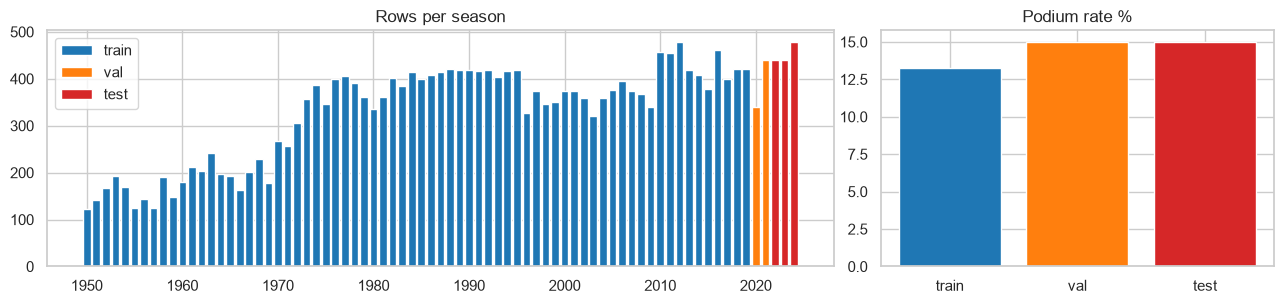

In [30]:
SPLITS = ["train", "val", "test"]
df["split"] = np.select([df["year"] <= 2019, df["year"] <= 2021], ["train", "val"], "test")

split_summary = df.groupby("split").agg(first_season=("year", "min"), last_season=("year", "max"),
                                         races=("raceId", "nunique"), rows=("podium", "size"),
                                         podium_rate=("podium", "mean")).loc[SPLITS]
display(split_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [2, 1]})
for name, color in zip(SPLITS, ["tab:blue", "tab:orange", "tab:red"]):
    seasons = df[df["split"] == name].groupby("year").size()
    axes[0].bar(seasons.index, seasons.values, color=color, label=name)
axes[0].set_title("Rows per season")
axes[0].legend()
axes[1].bar(SPLITS, 100 * split_summary["podium_rate"], color=["tab:blue", "tab:orange", "tab:red"])
axes[1].set_title("Podium rate %")
save("12_split")

In [31]:
def make_pipe(model, impute_first=True, indicators=True, scale=True):
    """Median imputation (+ missing-value indicator columns) and standard scaling, then the model."""
    impute = ("impute", SimpleImputer(strategy="median", add_indicator=indicators))
    steps = [impute, ("scale", StandardScaler())] if scale else [impute]
    if not impute_first:
        steps = steps[::-1]
    return Pipeline(steps + [("model", model)])


def best_f1_threshold(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]


def all_metrics(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, prob), "PR-AUC": average_precision_score(y_true, prob),
            "F1": f1_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred)}


def lr(**params):
    return LogisticRegression(max_iter=2000, **params)


def rf(**params):
    return RandomForestClassifier(n_estimators=300, max_features="sqrt", n_jobs=-1, random_state=SEED, **params)


def hgb(**params):
    # early stopping uses an internal 10% of the training rows, never the validation seasons
    return HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=SEED, **params)


def mlp(seed=SEED, **params):
    # shallow network: ReLU hidden layers, Adam, L2 penalty `alpha`, early stopping on 10% of the training rows
    return MLPClassifier(early_stopping=True, max_iter=300, random_state=seed, **params)


# fixed, reasonable settings used for the checks in Sections 8 and 9 (tuning happens in Section 10)
CHECK_MODELS = {"logistic regression": lr, "random forest": lambda: rf(min_samples_leaf=20),
                "neural net": lambda: mlp(hidden_layer_sizes=(32,))}

parts = {name: df[df["split"] == name] for name in SPLITS}
y = {name: part["podium"] for name, part in parts.items()}

## 8. Feature selection

We start with 27 candidate features in six groups and look at three things, all on **training seasons only**:

1. how much podium signal each feature carries on its own (ROC-AUC of the raw value, coverage),
2. which features are near-copies of each other (Spearman correlation),
3. whether the relationship with the podium rate has a sensible shape.

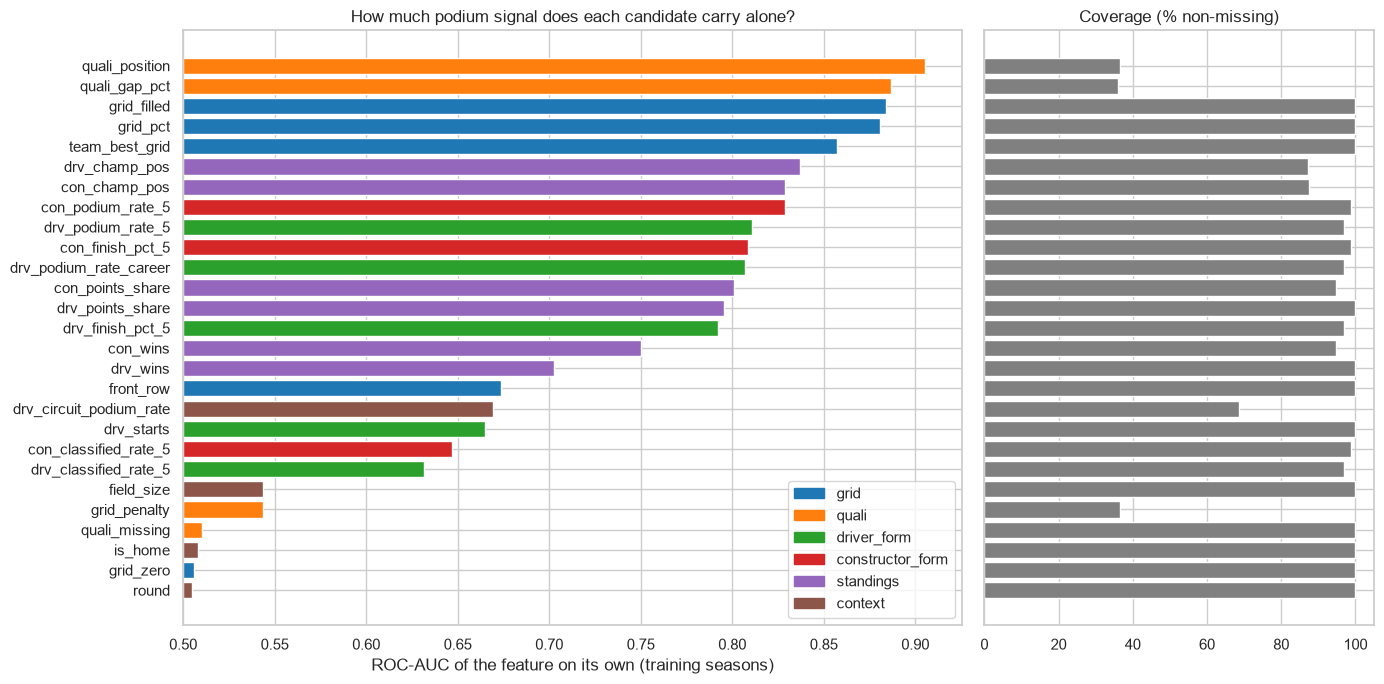

,feature,group,coverage %,AUC
5,quali_position,quali,36.643,0.905
6,quali_gap_pct,quali,36.059,0.887
0,grid_filled,grid,100.000,0.884
2,grid_pct,grid,100.000,0.881
4,team_best_grid,grid,100.000,0.857
18,drv_champ_pos,standings,87.323,0.837
21,con_champ_pos,standings,87.372,0.829
14,con_podium_rate_5,constructor_form,98.819,0.829
10,drv_podium_rate_5,driver_form,96.941,0.811
15,con_finish_pct_5,constructor_form,98.819,0.809


In [32]:
train = parts["train"]
signal = []
for group, feats in CANDIDATES.items():
    for f in feats:
        known = train[f].notna()
        auc = roc_auc_score(train.loc[known, "podium"], train.loc[known, f])
        signal.append({"feature": f, "group": group, "coverage %": 100 * known.mean(), "AUC": max(auc, 1 - auc)})
signal = pd.DataFrame(signal).sort_values("AUC", ascending=False)

colors = dict(zip(CANDIDATES, sns.color_palette("tab10")))
plot = signal.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [2, 1]})
axes[0].barh(plot["feature"], plot["AUC"] - 0.5, left=0.5, color=plot["group"].map(colors))
axes[0].set_xlabel("ROC-AUC of the feature on its own (training seasons)")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), loc="lower right")
axes[0].set_title("How much podium signal does each candidate carry alone?")
axes[1].barh(plot["feature"], plot["coverage %"], color="grey")
axes[1].set_title("Coverage (% non-missing)")
axes[1].set_yticklabels([])
save("13_feature_signal")
signal.round(3)

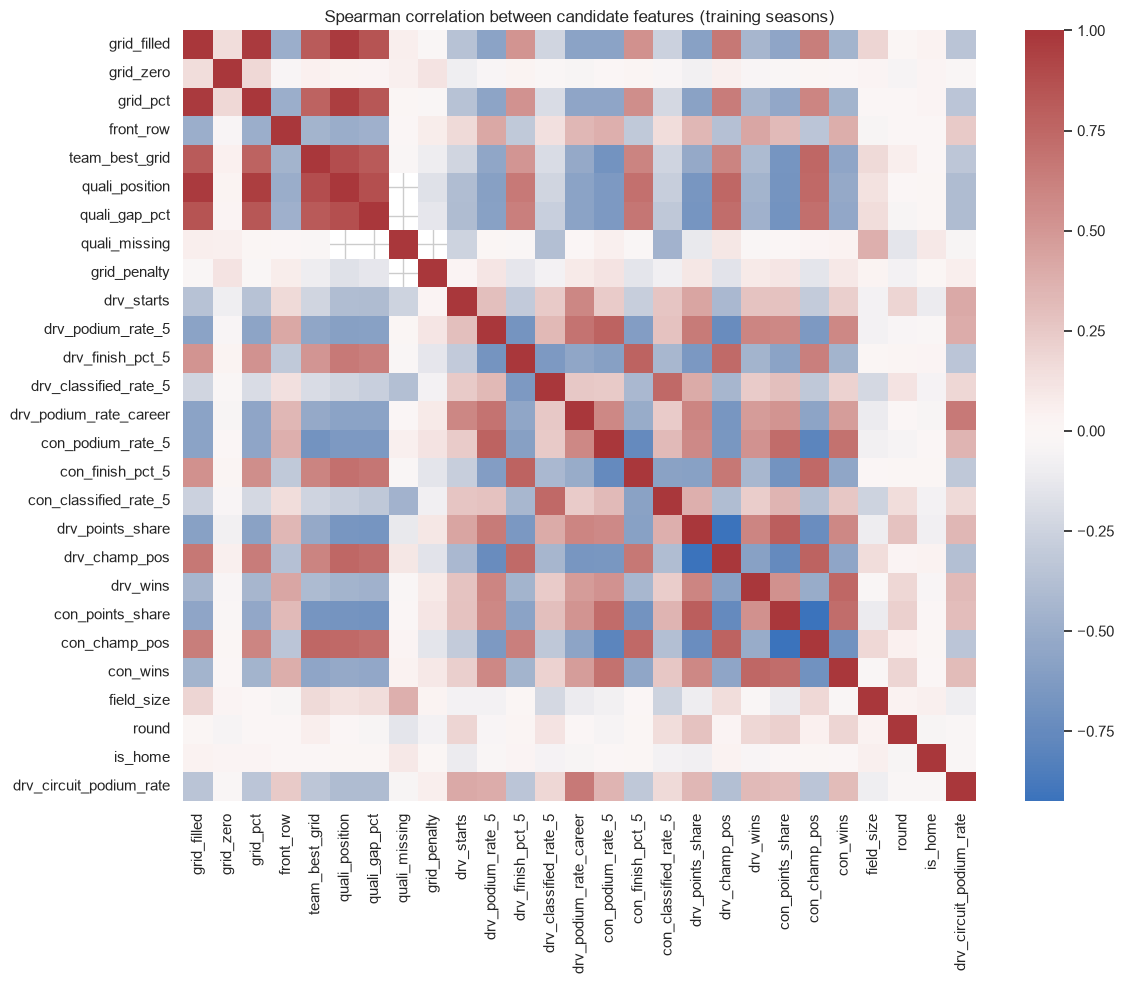

grid_filled       quali_position    0.975
                  grid_pct          0.971
grid_pct          quali_position    0.961
con_points_share  con_champ_pos    -0.924
drv_points_share  drv_champ_pos    -0.922
dtype: float64

In [33]:
corr = train[candidates].corr(method="spearman")
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, xticklabels=True, yticklabels=True)
plt.title("Spearman correlation between candidate features (training seasons)")
save("14_feature_correlation")

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() >= 0.9].sort_values(key=abs, ascending=False).round(3)

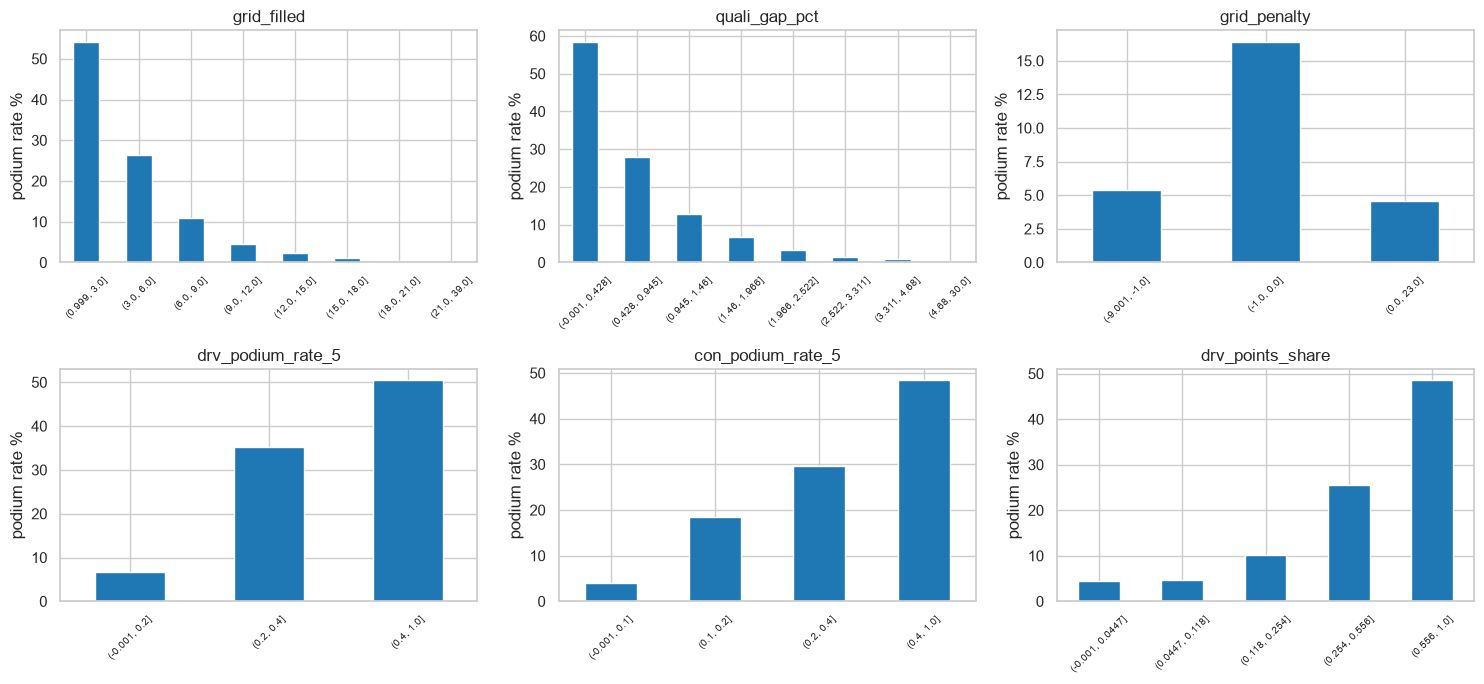

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, f in zip(axes.ravel(), ["grid_filled", "quali_gap_pct", "grid_penalty",
                                "drv_podium_rate_5", "con_podium_rate_5", "drv_points_share"]):
    bins = pd.qcut(train[f], 8, duplicates="drop")
    (100 * train.groupby(bins, observed=True)["podium"].mean()).plot.bar(ax=ax, color="tab:blue")
    ax.set_title(f)
    ax.set_xlabel("")
    ax.set_ylabel("podium rate %")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
save("15_feature_shapes")

**Decision.** The evidence above leads us to drop six candidates:

| Dropped | Why |
|---|---|
| `grid_pct` | rho = 0.971 with `grid_filled`: the same ordering divided by the field size |
| `quali_position` | rho = 0.975 with `grid_filled`, and missing for 63% of training rows. The *difference* between qualifying and grid, which Q1 showed matters, is kept as `grid_penalty` |
| `drv_champ_pos`, `con_champ_pos` | rho = -0.92 with the matching points share: the same information upside down |
| `round` | AUC 0.505 on its own, i.e. no signal |
| `is_home` | AUC 0.508 on its own, and Q2 found no home effect once the grid is controlled |

Everything we keep either carries signal on its own (AUC 0.54 to 0.89) or is needed to read another feature correctly: `grid_zero` tells the model that `grid_filled` was filled in, and `quali_missing` tells it that the qualifying features were imputed. The binned plots show the shapes we expected: the podium rate falls steeply with the grid slot and the gap to pole, and rises with recent driver/team form and the points share. `grid_penalty` is the exception: drivers who start exactly where they qualified podium most often (about 16%), while both promoted and demoted drivers podium less (about 5%), so its effect is not a straight line and depends on where on the grid the change happens.

**The 21 features we keep, and why each one is known before the start:**

| Feature | Group | Meaning | Known before the start because |
|---|---|---|---|
| `grid_filled` | grid | grid slot; 0 (no slot / pit lane) becomes field size + 1 | the grid is final before the start |
| `grid_zero` | grid | 1 if the official grid value was 0 | same |
| `front_row` | grid | 1 if starting P1 or P2 | same |
| `team_best_grid` | grid | best grid slot of the team's cars in this race (a car-pace proxy) | both cars' slots are on the grid |
| `quali_gap_pct` | quali | % slower than the fastest qualifying lap of the race (capped at 30) | qualifying is over |
| `quali_missing` | quali | 1 if there is no qualifying row (mostly before 1994) | describes the data, not the race |
| `grid_penalty` | quali | grid slot minus qualifying position (> 0 = started further back) | both are known |
| `drv_starts` | driver_form | number of earlier starts | earlier races only |
| `drv_podium_rate_5` | driver_form | podium share in the last 5 starts | earlier races only (`shift(1)`) |
| `drv_finish_pct_5` | driver_form | average finishing position / field size, last 5 starts | earlier races only |
| `drv_classified_rate_5` | driver_form | share of the last 5 starts that were classified (reliability) | earlier races only |
| `drv_podium_rate_career` | driver_form | podium share over all earlier starts | earlier races only |
| `con_podium_rate_5` | constructor_form | team podium share over its last 5 races | earlier races only, team aggregated per race first |
| `con_finish_pct_5` | constructor_form | team average finishing position / field size, last 5 races | earlier races only |
| `con_classified_rate_5` | constructor_form | team share of classified cars, last 5 races | earlier races only |
| `drv_points_share` | standings | driver points / leader's points after the latest earlier round of the season | standings of earlier rounds only |
| `drv_wins` | standings | driver wins so far this season | same |
| `con_points_share` | standings | constructor points / leader's points (from 1958) | same |
| `con_wins` | standings | constructor wins so far this season (from 1958) | same |
| `field_size` | context | number of starters in this race | the starting list is fixed after qualifying |
| `drv_circuit_podium_rate` | context | driver's podium share at this circuit in earlier visits | earlier races only |

In [35]:
DROPPED = {
    "grid_pct": "same ordering as grid_filled (rho 0.971)",
    "quali_position": "same ordering as grid_filled (rho 0.975), missing before 1994; grid_penalty keeps the difference",
    "drv_champ_pos": "mirror image of drv_points_share (rho -0.922)",
    "con_champ_pos": "mirror image of con_points_share (rho -0.924)",
    "round": "no signal on its own (AUC 0.505)",
    "is_home": "no signal on its own (AUC 0.508) and Q2 found no home effect",
}
FEATURE_GROUPS = {group: [f for f in feats if f not in DROPPED] for group, feats in CANDIDATES.items()}
FEATURES = [f for feats in FEATURE_GROUPS.values() for f in feats]
GROUP_OF = {f: group for group, feats in FEATURE_GROUPS.items() for f in feats}
X = {name: part[FEATURES] for name, part in parts.items()}
print(len(FEATURES), "features:", FEATURES)

21 features: ['grid_filled', 'grid_zero', 'front_row', 'team_best_grid', 'quali_gap_pct', 'quali_missing', 'grid_penalty', 'drv_starts', 'drv_podium_rate_5', 'drv_finish_pct_5', 'drv_classified_rate_5', 'drv_podium_rate_career', 'con_podium_rate_5', 'con_finish_pct_5', 'con_classified_rate_5', 'drv_points_share', 'drv_wins', 'con_points_share', 'con_wins', 'field_size', 'drv_circuit_podium_rate']


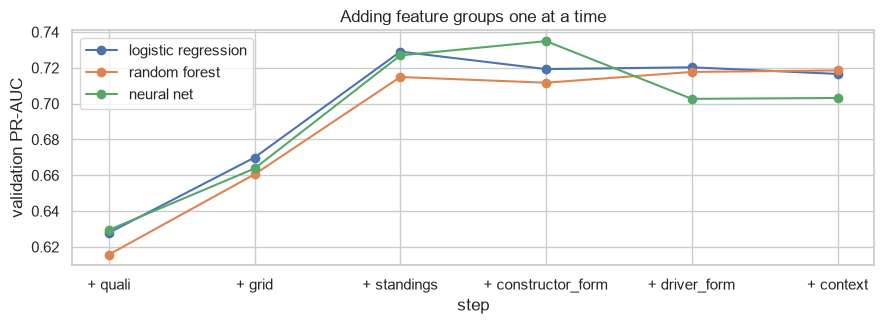

,features,logistic regression,random forest,neural net
step,,,,
+ quali,3,0.6279,0.6157,0.6294
+ grid,7,0.6699,0.6605,0.6638
+ standings,11,0.7291,0.7149,0.7270
+ constructor_form,14,0.7193,0.7117,0.7349
+ driver_form,19,0.7203,0.7177,0.7027
+ context,21,0.7166,0.7186,0.7032


,logistic regression,random forest,neural net,mean
all 27 candidates,0.7264,0.7183,0.7176,0.7208
selected 21,0.7166,0.7170,0.7208,0.7181


In [36]:
def val_pr_auc(features, model, train_rows=None):
    train_rows = parts["train"] if train_rows is None else train_rows
    pipe = make_pipe(model).fit(train_rows[features], train_rows["podium"])
    return average_precision_score(y["val"], pipe.predict_proba(parts["val"][features])[:, 1])


# trial 1: add the groups one by one (strongest first) and keep every step for the record
trial, used = [], []
for group in signal.groupby("group")["AUC"].max().sort_values(ascending=False).index:
    used = used + FEATURE_GROUPS[group]
    trial.append({"step": f"+ {group}", "features": len(used),
                  **{name: val_pr_auc(used, make()) for name, make in CHECK_MODELS.items()}})
trial = pd.DataFrame(trial).set_index("step")

# trial 2: does dropping the six features cost anything?
dropping = pd.DataFrame({f"all {len(candidates)} candidates": {name: val_pr_auc(candidates, make()) for name, make in CHECK_MODELS.items()},
                         f"selected {len(FEATURES)}": {name: val_pr_auc(FEATURES, make()) for name, make in CHECK_MODELS.items()}}).T
dropping["mean"] = dropping.mean(axis=1)

trial[list(CHECK_MODELS)].plot(marker="o", figsize=(9, 3.4))
plt.ylabel("validation PR-AUC")
plt.title("Adding feature groups one at a time")
save("16_group_trial")
display(trial.round(4))
dropping.round(4)

**Reading the trials** (validation PR-AUC, three model families with fixed settings):

* Starting-order information does most of the work. The qualifying group alone reaches 0.62-0.63, adding the grid group brings all three models to 0.66-0.67, and the championship standings add the next big step (0.715-0.729).
* After that the groups help some models and not others. Constructor form lifts the neural net to 0.735 but not the other two; driver form and context move the three models in different directions (between -0.03 and +0.01). Section 11 measures every group again after tuning.
* **Dropping the six features costs nothing measurable:** the mean over the three models is 0.7181 with the selected 21 features and 0.7208 with all 27 candidates. That 0.003 is smaller than what we get just by changing a random seed (Section 11), so we keep the smaller, less redundant set.

## 9. Preprocessing

All models share one preprocessing pipeline, fitted on the training rows only:

1. **Median imputation with missing-indicator columns.** The median is not pulled around by the long tails we saw (e.g. `quali_gap_pct`, `drv_starts`), and the indicator lets a model tell "no qualifying data / first race" apart from a real median value.
2. **Standard scaling.** Needed by logistic regression and the neural network (gradient-based training); the tree models don't care but get the same input so that every model sees the same features.

Below: the effect of these steps on the distributions and ranges.

33 columns after preprocessing; indicator columns were added for ['quali_gap_pct', 'grid_penalty', 'drv_podium_rate_5', 'drv_finish_pct_5', 'drv_classified_rate_5', 'drv_podium_rate_career', 'con_podium_rate_5', 'con_finish_pct_5', 'con_classified_rate_5', 'con_points_share', 'con_wins', 'drv_circuit_podium_rate']


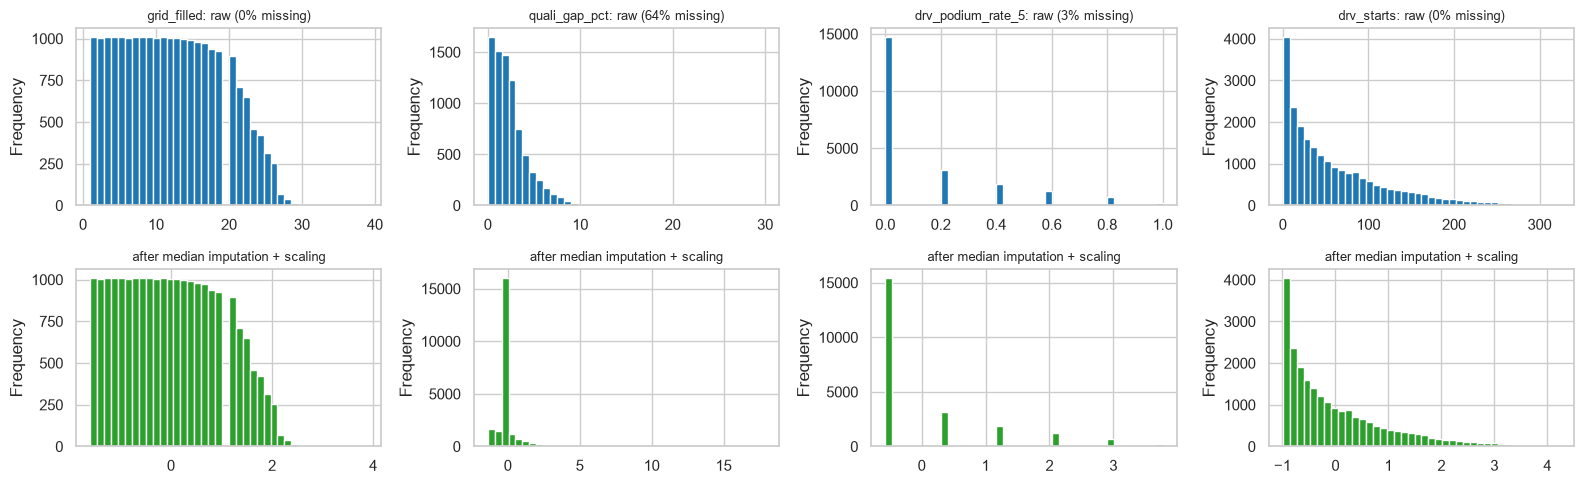

,raw min,raw max,raw mean,raw % missing,processed mean,processed std
grid_filled,1.00,39.00,12.05,0.00,-0.0,1.0
grid_zero,0.00,1.00,0.01,0.00,-0.0,1.0
front_row,0.00,1.00,0.09,0.00,-0.0,1.0
team_best_grid,1.00,34.00,9.48,0.00,0.0,1.0
quali_gap_pct,0.00,30.00,2.51,63.94,-0.0,1.0
quali_missing,0.00,1.00,0.63,0.00,0.0,1.0
grid_penalty,-9.00,23.00,0.01,63.36,-0.0,1.0
drv_starts,0.00,324.00,61.52,0.00,0.0,1.0
drv_podium_rate_5,0.00,1.00,0.14,3.06,-0.0,1.0
drv_finish_pct_5,0.03,1.04,0.52,3.06,0.0,1.0


In [37]:
prep = make_pipe("passthrough").fit(X["train"])
processed = pd.DataFrame(prep.transform(X["train"]), columns=prep.get_feature_names_out(), index=X["train"].index)
print(processed.shape[1], "columns after preprocessing; indicator columns were added for",
      [c.replace("missingindicator_", "") for c in processed.columns if c.startswith("missingindicator_")])

show = ["grid_filled", "quali_gap_pct", "drv_podium_rate_5", "drv_starts"]
fig, axes = plt.subplots(2, len(show), figsize=(16, 5))
for i, f in enumerate(show):
    X["train"][f].plot.hist(bins=40, ax=axes[0, i], color="tab:blue")
    axes[0, i].set_title(f"{f}: raw ({X['train'][f].isna().mean():.0%} missing)", fontsize=9)
    processed[f].plot.hist(bins=40, ax=axes[1, i], color="tab:green")
    axes[1, i].set_title("after median imputation + scaling", fontsize=9)
save("17_preprocessing_effect")

pd.DataFrame({"raw min": X["train"].min(), "raw max": X["train"].max(), "raw mean": X["train"].mean(),
              "raw % missing": 100 * X["train"].isna().mean(),
              "processed mean": processed[FEATURES].mean(), "processed std": processed[FEATURES].std()}).round(2)

### 9.1 Preprocessing-order experiments

To isolate the effect of preprocessing we keep the learner fixed (plain logistic regression) and only change one thing at a time. Decisions are made on **validation**; test is shown for reference only.

* **E1, fit order:** split first and fit the imputer/scaler on train only, or fit them on all seasons and split afterwards (leaky).
* **E2, step order:** impute then scale, or scale then impute.
* **E3, ingredients:** no missing indicators; no scaling.
* **E4, training window:** use all seasons, or only the seasons where qualifying data exists (1994+, complete from 2003). The row selection happens before the preprocessing is fitted.

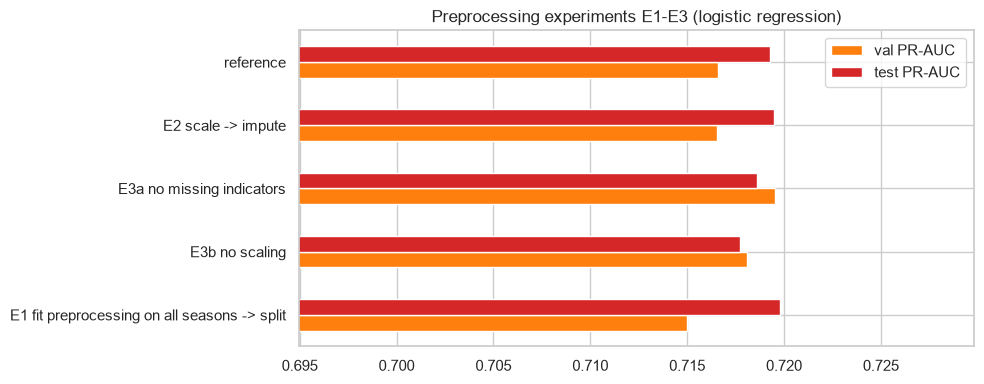

,val PR-AUC,val ROC-AUC,test PR-AUC,test ROC-AUC
reference,0.7166,0.9304,0.7193,0.9377
E2 scale -> impute,0.7165,0.9301,0.7195,0.9377
E3a no missing indicators,0.7195,0.9281,0.7186,0.9374
E3b no scaling,0.7181,0.9305,0.7178,0.9375
E1 fit preprocessing on all seasons -> split,0.7150,0.9303,0.7198,0.9378


In [38]:
def scores(predict):
    p_val, p_test = predict(X["val"]), predict(X["test"])
    return {"val PR-AUC": average_precision_score(y["val"], p_val), "val ROC-AUC": roc_auc_score(y["val"], p_val),
            "test PR-AUC": average_precision_score(y["test"], p_test), "test ROC-AUC": roc_auc_score(y["test"], p_test)}


experiments = {}

# reference: split -> fit on train; impute -> scale; with missing indicators
# each experiment changes exactly one thing
for name, options in [("reference", {}),
                      ("E2 scale -> impute", {"impute_first": False}),
                      ("E3a no missing indicators", {"indicators": False}),
                      ("E3b no scaling", {"scale": False})]:
    pipe = make_pipe(lr(), **options).fit(X["train"], y["train"])
    experiments[name] = scores(lambda x: pipe.predict_proba(x)[:, 1])

# E1: fit the imputer/scaler on every season first, then split (leaky order)
prep_all = make_pipe("passthrough").fit(df[FEATURES])
model = lr().fit(prep_all.transform(X["train"]), y["train"])
experiments["E1 fit preprocessing on all seasons -> split"] = scores(lambda x: model.predict_proba(prep_all.transform(x))[:, 1])

experiments = pd.DataFrame(experiments).T
experiments[["val PR-AUC", "test PR-AUC"]].iloc[::-1].plot.barh(figsize=(10, 4), color=["tab:orange", "tab:red"])
plt.xlim(experiments[["val PR-AUC", "test PR-AUC"]].min().min() - 0.02, experiments[["val PR-AUC", "test PR-AUC"]].max().max() + 0.01)
plt.title("Preprocessing experiments E1-E3 (logistic regression)")
save("18_preprocessing_experiments")
experiments.round(4)

**What E1-E3 show.**

* **E1, fit order.** Fitting the imputer and scaler on every season before splitting changes validation PR-AUC by only -0.002 (0.7150 vs 0.7166). Adding five seasons to seventy hardly moves a median or a standard deviation, so the leak is small here. We still fit on the training rows only: that is the only version that exists when a new race comes along, and for target-aware steps (e.g. target encoding) the same mistake would leak a lot more.
* **E2, step order.** Scaling before imputing gives 0.7165 against 0.7166. The only difference is whether the imputed values are counted when the scaler computes its mean and standard deviation; that shifts the scale a little but not the order of the values, so a linear model barely notices.
* **E3, ingredients.** Without missing indicators validation PR-AUC moves +0.003 but ROC-AUC drops (0.9281 vs 0.9304); without scaling it moves +0.0015. Both are within noise for logistic regression. We keep the indicators because they let a model tell "no qualifying data / first race" apart from a real median value, and we keep scaling because the neural network trains with gradient descent and needs inputs on a similar scale.

Overall, preprocessing choices move validation PR-AUC by at most 0.003, much less than the choice of feature groups (Section 8) or model (Section 10).

In [39]:
# E4: training window. The rows are selected before the preprocessing is fitted.
# The window affects every model, so we check it with all three model families.
windows = {}
for start in [1950, 1994, 2003]:
    rows = parts["train"][parts["train"]["year"] >= start]
    windows[start] = {"train rows": len(rows), **{name: val_pr_auc(FEATURES, make(), rows) for name, make in CHECK_MODELS.items()}}
windows = pd.DataFrame(windows).T.rename_axis("first training season")
windows["mean"] = windows[list(CHECK_MODELS)].mean(axis=1)

TRAIN_FROM = int(windows["mean"].idxmax())               # best average validation PR-AUC
parts["train"] = parts["train"][parts["train"]["year"] >= TRAIN_FROM]
X["train"], y["train"] = parts["train"][FEATURES], parts["train"]["podium"]
print(f"training window: {TRAIN_FROM}-2019, {len(parts['train']):,} rows")
windows.round(4)

training window: 2003-2019, 6,827 rows


,train rows,logistic regression,random forest,neural net,mean
first training season,,,,,
1950,22782.0,0.7166,0.7170,0.7208,0.7181
1994,10165.0,0.7205,0.7152,0.6830,0.7062
2003,6827.0,0.7246,0.7213,0.7277,0.7245


**E4, training window.** Training on 2003-2019 gives the best average validation PR-AUC (0.7245, against 0.7181 for all seasons and 0.7062 for 1994+), so the code above keeps those seasons for every model from here on.

The gain is small (about 0.006, similar to seed-to-seed noise), so this is partly a judgement call. We follow the validation result because it agrees with the EDA: from 2003 every race has qualifying data, while the earlier decades (bigger fields, far worse reliability, no qualifying table) behave differently from the seasons we want to predict. The price is a smaller training set, 6,827 rows instead of 22,782. The feature evidence in Section 8 was computed on all training seasons, and the features themselves are defined the same way for every season.

## 10. Models

Every model below uses the same rows, the same features and the same preprocessing. Hyperparameters are chosen by **validation PR-AUC**, and the F1 threshold is the one that maximises F1 on **validation**; the test seasons are never used for either.

| Model | How it works | Main limitation here |
|---|---|---|
| Rule: grid <= 3 | no learning, predicts a podium for the top three starters | ignores car pace, form and reliability |
| Logistic regression (**baseline**) | a weighted sum of the features passed through a sigmoid; each weight is a change in log-odds | cannot model interactions (grid x team strength) or curved effects unless we build them by hand |
| Random forest | hundreds of decision trees on bootstrap samples; the probability is the average vote | many deep trees are hard to inspect; no extrapolation to unseen value ranges |
| Gradient boosting | small trees added one after another, each fitting the errors of the ones before | easy to overfit without early stopping / regularisation |
| Shallow neural network | 1-2 hidden ReLU layers trained with Adam, L2 penalty and early stopping | needs scaled, imputed inputs; less transparent; results move a little with the random seed |

The logistic regression with default settings is our **baseline**: the simplest reasonable model. Every other model has to beat it to justify its extra complexity.

In [40]:
score_rows, fitted = [], {}


def fit_and_score(name, pipe):
    pipe.fit(X["train"], y["train"])
    probs = {s: pipe.predict_proba(X[s])[:, 1] for s in SPLITS}
    threshold = best_f1_threshold(y["val"], probs["val"])         # chosen on validation only
    for s in SPLITS:
        score_rows.append({"model": name, "split": s, "threshold": threshold, **all_metrics(y[s], probs[s], threshold)})
    fitted[name] = {"pipe": pipe, "probs": probs, "threshold": threshold}


def tune(make_model, grid):
    """Fit every combination on train, rank by validation PR-AUC, return the best parameters."""
    results = []
    for params in ParameterGrid(grid):
        pipe = make_pipe(make_model(**params)).fit(X["train"], y["train"])
        results.append((average_precision_score(y["val"], pipe.predict_proba(X["val"])[:, 1]), params))
    results.sort(key=lambda r: r[0], reverse=True)
    display(pd.DataFrame([{**{k: str(v) for k, v in params.items()}, "val PR-AUC": score}
                          for score, params in results]).head(5).round(4))
    return results[0][1]


# reference rule, no learning: "the top 3 on the grid finish on the podium"
for s in SPLITS:
    score_rows.append({"model": "Rule: grid <= 3", "split": s, "threshold": np.nan,
                       **all_metrics(y[s], -parts[s]["grid_filled"], -3)})

# attempt 1: baseline
fit_and_score("Logistic regression (baseline)", make_pipe(lr()))

In [41]:
# attempt 2: tuned logistic regression
best_lr = tune(lr, {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]})
fit_and_score("Logistic regression (tuned)", make_pipe(lr(**best_lr)))
print("chosen:", best_lr)

,C,class_weight,val PR-AUC
0,1,balanced,0.7275
1,0.1,balanced,0.7267
2,10,balanced,0.7263
3,10,None,0.7247
4,1,None,0.7246


chosen: {'C': 1, 'class_weight': 'balanced'}


In [42]:
# attempt 3: random forest
best_rf = tune(rf, {"max_depth": [6, 10, None], "min_samples_leaf": [5, 20, 50]})
fit_and_score("Random forest (tuned)", make_pipe(rf(**best_rf)))
print("chosen:", best_rf)

,max_depth,min_samples_leaf,val PR-AUC
0,None,20,0.7213
1,10,20,0.7207
2,6,20,0.7205
3,None,50,0.7204
4,10,50,0.7185


chosen: {'max_depth': None, 'min_samples_leaf': 20}


In [43]:
# attempt 4: gradient boosting
best_hgb = tune(hgb, {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 15, 31], "l2_regularization": [0.0, 1.0]})
fit_and_score("Gradient boosting (tuned)", make_pipe(hgb(**best_hgb)))
print("chosen:", best_hgb)

,l2_regularization,learning_rate,max_leaf_nodes,val PR-AUC
0,1.0,0.03,15,0.7340
1,1.0,0.03,7,0.7320
2,0.0,0.03,15,0.7309
3,1.0,0.03,31,0.7303
4,0.0,0.03,7,0.7284


chosen: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15}


In [44]:
# attempts 5 and 6: shallow neural network
fit_and_score("Neural net (baseline, 1x32)", make_pipe(mlp(hidden_layer_sizes=(32,))))
best_mlp = tune(mlp, {"hidden_layer_sizes": [(32,), (64,), (64, 32)], "alpha": [0.0001, 0.001, 0.01, 0.1]})
fit_and_score("Neural net (tuned)", make_pipe(mlp(**best_mlp)))
print("chosen:", best_mlp)

,alpha,hidden_layer_sizes,val PR-AUC
0,0.001,"(64, 32)",0.7309
1,0.001,"(32,)",0.7280
2,0.0001,"(32,)",0.7277
3,0.01,"(32,)",0.7276
4,0.1,"(64, 32)",0.7240


chosen: {'alpha': 0.001, 'hidden_layer_sizes': (64, 32)}


### 10.1 Comparison on train, validation and the unseen test seasons

**Primary metric: PR-AUC.** Only 13-15% of rows are podiums. PR-AUC measures how well the real podium finishers are ranked at the top of each race's field, ignores the many easy "back of the grid" negatives and needs no threshold.
**Secondary: ROC-AUC**, the overall separation of the two classes (it looks high for every model because most negatives are easy).
**F1, precision and recall** are reported at the threshold chosen on validation, applied unchanged to train and test.

In [45]:
METRICS = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]
scores_long = pd.DataFrame(score_rows)
comparison = scores_long.pivot_table(index="model", columns="split", values=METRICS, sort=False)
comparison = comparison.reindex(columns=pd.MultiIndex.from_product([METRICS, SPLITS]))

tuned = [name for name in fitted if "tuned" in name]
PRIMARY = max(tuned, key=lambda name: comparison.loc[name, ("PR-AUC", "val")])
print("primary model (highest validation PR-AUC among the tuned models):", PRIMARY)
comparison.round(3)

primary model (highest validation PR-AUC among the tuned models): Gradient boosting (tuned)


ROC-AUC               PR-AUC                   F1               Precision               Recall              
                                 train    val   test  train    val   test  train    val   test     train    val   test  train    val   test
model                                                                                                                                      
Rule: grid <= 3                  0.909  0.909  0.914  0.626  0.639  0.647  0.646  0.692  0.649     0.647  0.692  0.650  0.646  0.692  0.647
Logistic regression (baseline)   0.933  0.932  0.940  0.698  0.725  0.720  0.667  0.704  0.674     0.573  0.669  0.585  0.799  0.744  0.794
Logistic regression (tuned)      0.933  0.931  0.939  0.692  0.727  0.716  0.666  0.699  0.669     0.571  0.659  0.581  0.800  0.744  0.789
Random forest (tuned)            0.955  0.932  0.939  0.776  0.721  0.707  0.719  0.714  0.691     0.663  0.702  0.648  0.785  0.726  0.740
Gradient boosting (tuned)        0.957  0.933  0.938  0.790  0.734  0.711  0.718  0.707  0.672     0.719  0.723  0.693  0.717  0.692  0.652
Neural net (baseline, 1x32)      0.933  0.923  0.933  0.693  0.728  0.686  0.668  0.715  0.654     0.587  0.674  0.585  0.776  0.761  0.740
Neural net (tuned)               0.938  0.926  0.932  0.715  0.731  0.713  0.675  0.704  0.648     0.592  0.662  0.571  0.785  0.752  0.750

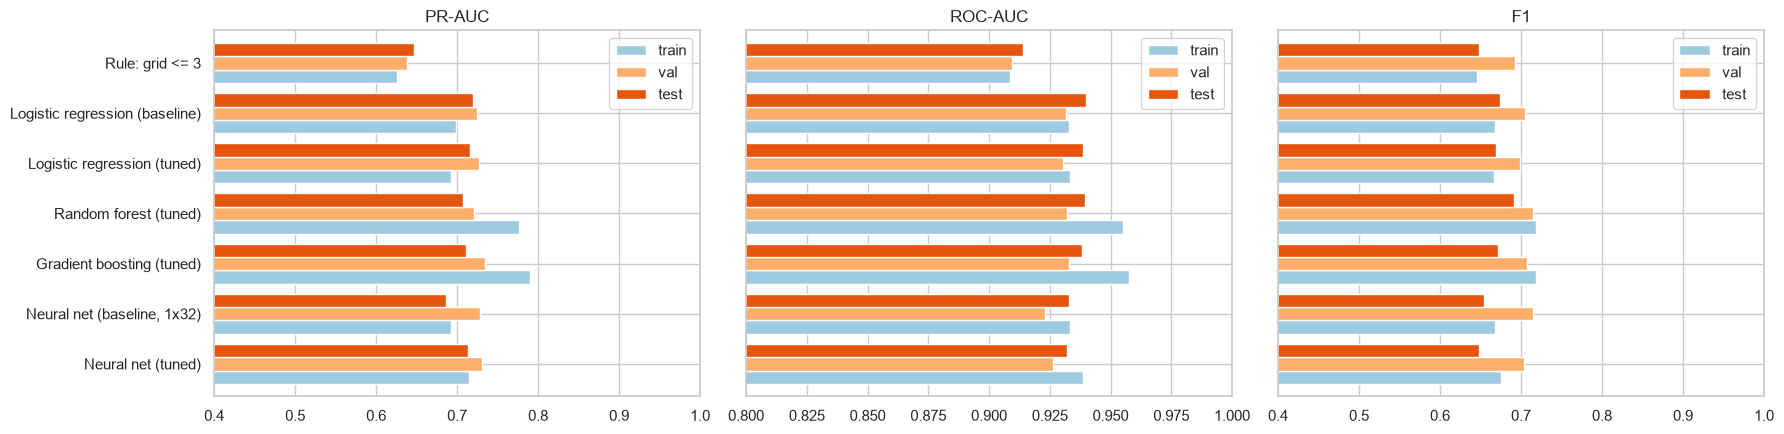

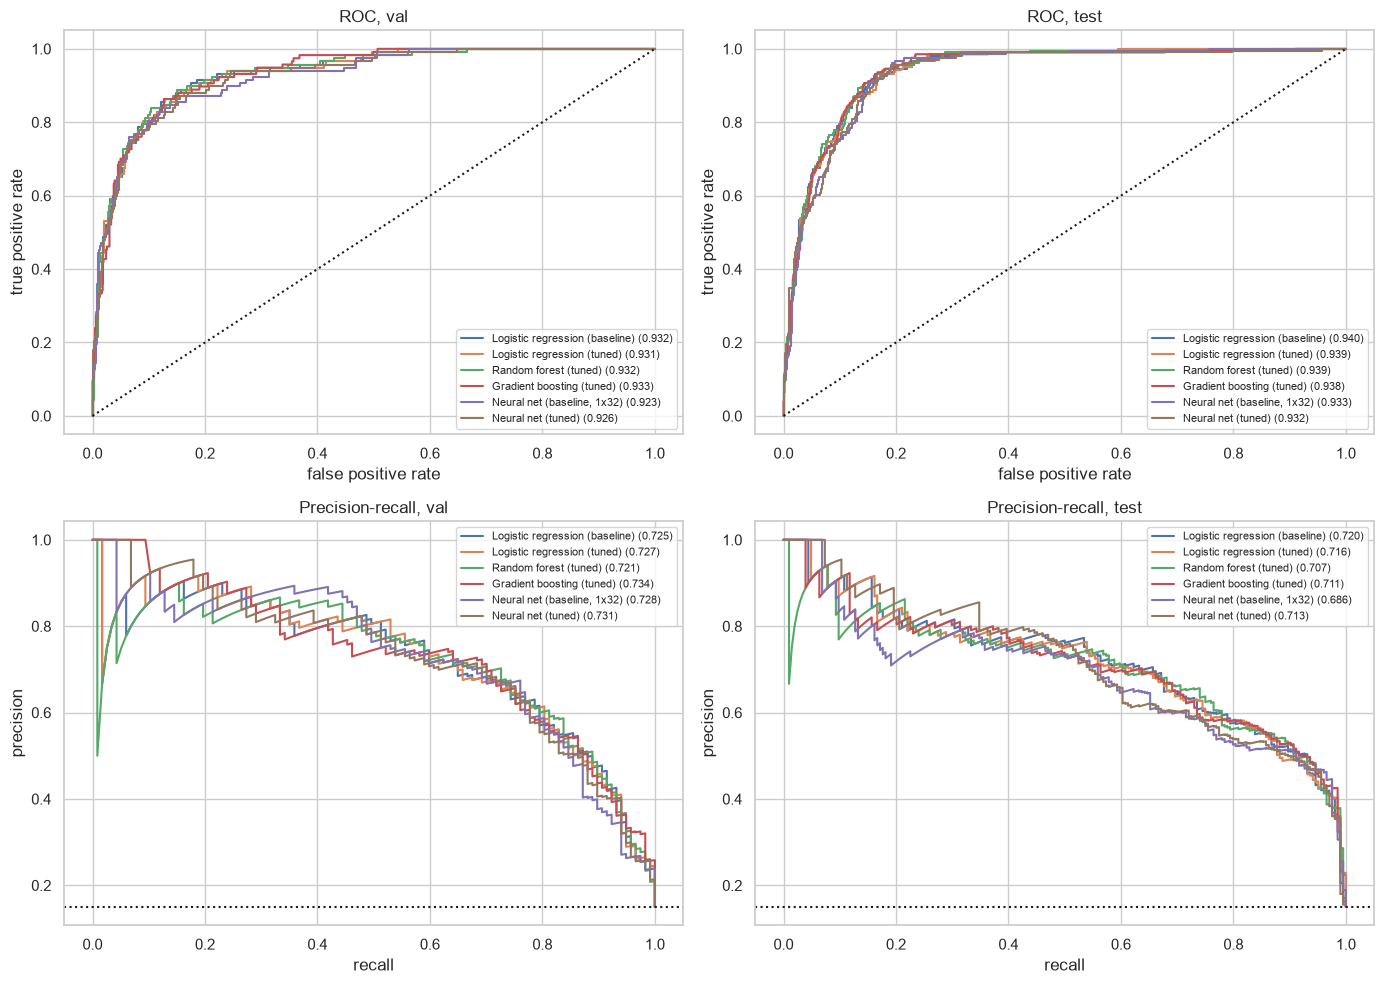

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC", "F1"]):
    comparison[metric].iloc[::-1].plot.barh(ax=ax, color=["#9ecae1", "#fdae6b", "#e6550d"], width=0.8)
    ax.set_xlim(0.4 if metric != "ROC-AUC" else 0.8, 1.0)
    ax.set_title(metric)
    ax.set_ylabel("")
save("19_model_comparison")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, s in enumerate(["val", "test"]):
    for name in fitted:
        p = fitted[name]["probs"][s]
        fpr, tpr, _ = roc_curve(y[s], p)
        precision, recall, _ = precision_recall_curve(y[s], p)
        axes[0, col].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y[s], p):.3f})")
        axes[1, col].plot(recall, precision, label=f"{name} ({average_precision_score(y[s], p):.3f})")
    axes[0, col].plot([0, 1], [0, 1], "k:")
    axes[0, col].set(title=f"ROC, {s}", xlabel="false positive rate", ylabel="true positive rate")
    axes[1, col].axhline(y[s].mean(), color="k", ls=":")
    axes[1, col].set(title=f"Precision-recall, {s}", xlabel="recall", ylabel="precision")
    axes[0, col].legend(fontsize=8)
    axes[1, col].legend(fontsize=8)
save("20_roc_pr_curves")

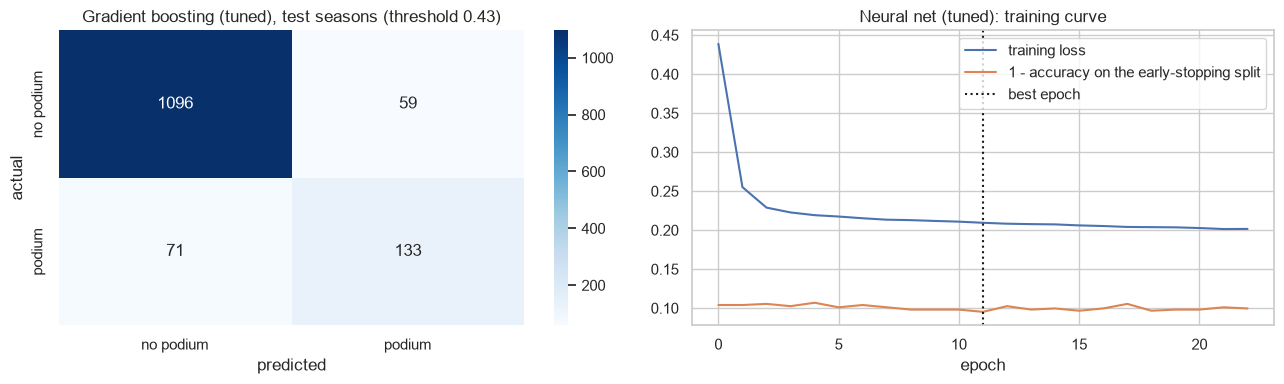

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
best = fitted[PRIMARY]
matrix = confusion_matrix(y["test"], best["probs"]["test"] >= best["threshold"])
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["no podium", "podium"], yticklabels=["no podium", "podium"])
axes[0].set(xlabel="predicted", ylabel="actual", title=f"{PRIMARY}, test seasons (threshold {best['threshold']:.2f})")

net = fitted["Neural net (tuned)"]["pipe"][-1]
axes[1].plot(net.loss_curve_, label="training loss")
axes[1].plot(1 - np.array(net.validation_scores_), label="1 - accuracy on the early-stopping split")
axes[1].axvline(np.argmax(net.validation_scores_), color="k", ls=":", label="best epoch")
axes[1].set(xlabel="epoch", title="Neural net (tuned): training curve")
axes[1].legend()
save("21_confusion_and_training_curve")

In [48]:
# PR-AUC of the primary model per period: are older seasons simply harder to rank?
train_view = parts["train"].assign(p=fitted[PRIMARY]["probs"]["train"])
eras = pd.cut(train_view["year"], [1949, 1979, 1993, 2013, 2019])
by_era = {f"{g['year'].min()}-{g['year'].max()} (train)": average_precision_score(g["podium"], g["p"])
          for _, g in train_view.groupby(eras, observed=True)}
by_era["2020-21 (val)"] = average_precision_score(y["val"], fitted[PRIMARY]["probs"]["val"])
by_era["2022-24 (test)"] = average_precision_score(y["test"], fitted[PRIMARY]["probs"]["test"])
pd.Series(by_era, name=f"PR-AUC of {PRIMARY}").round(3)

2003-2013 (train)    0.766
2014-2019 (train)    0.828
2020-21 (val)        0.734
2022-24 (test)       0.711
Name: PR-AUC of Gradient boosting (tuned), dtype: float64

**Reading the comparison.**

* **Primary model: gradient boosting**, the tuned model with the highest validation PR-AUC (0.734; neural net 0.731, logistic regression 0.727, random forest 0.721). On the unseen 2022-2024 seasons it reaches PR-AUC 0.711 and ROC-AUC 0.938. At the threshold chosen on validation (0.43) it predicts 192 podiums on the test seasons, 133 of them correct (precision 0.69), and finds 133 of the 204 real podiums (recall 0.65, F1 0.67).
* **Learning clearly beats the simple rule.** "Top three on the grid" already reaches test PR-AUC 0.647. Every learned model lands between 0.686 and 0.720, and ROC-AUC goes from 0.914 to about 0.94: recent form, team strength and standings tell the model which front-runners are likely to stay there and who can come from further back.
* **The extra complexity does not clearly pay off.** On the test seasons the plain logistic-regression baseline is actually the best (0.720), and every tuned model is within 0.013 of it. That is about the size of the seed-to-seed noise (+/-0.007 for the neural net) with only 68 test races. We keep gradient boosting as the primary model because that is what our validation rule picked, not because it is clearly better; the baseline would serve just as well here.
* **Different threshold trade-offs.** With its validation threshold, logistic regression catches more podiums (test recall 0.79) at lower precision (0.59), while gradient boosting is more conservative (0.65 / 0.69). The random forest has the best test F1 (0.69).
* **Overfitting check.** The two tree models fit the training seasons noticeably better than validation (PR-AUC 0.79 and 0.78 against 0.73 and 0.72). Logistic regression and the networks show no such gap; their training score is even a bit lower than validation, because the 2003-2013 part of the training data is harder to rank than recent seasons (PR-AUC by period: 0.766 for 2003-2013 against 0.828 for 2014-2019). The network stopped training after 10 epochs without improvement on its early-stopping split and kept the weights from its best epoch (dotted line in the training-curve plot).

## 11. Feature-group ablation

Section 8 justified the features *before* training. Here we measure what each group actually contributes *after* training: we remove one group at a time, retrain with the same tuned hyperparameters and compare PR-AUC with the full model. Because grid and qualifying carry overlapping information, we also remove the two together. To judge which changes are real, we refit the neural net with five different seeds.

In [49]:
TUNED = {
    "Logistic regression": lambda: lr(**best_lr),
    "Gradient boosting": lambda: hgb(**best_hgb),
    "Neural net": lambda: mlp(**best_mlp),
}
scenarios = {"all features": FEATURES}
for group in FEATURE_GROUPS:
    scenarios[f"without {group}"] = [f for f in FEATURES if GROUP_OF[f] != group]
scenarios["without grid + quali"] = [f for f in FEATURES if GROUP_OF[f] not in ("grid", "quali")]

ablation = []
for model_name, make_model in TUNED.items():
    for scenario, feats in scenarios.items():
        pipe = make_pipe(make_model()).fit(parts["train"][feats], y["train"])
        ablation.append({"model": model_name, "scenario": scenario,
                         "val PR-AUC": average_precision_score(y["val"], pipe.predict_proba(parts["val"][feats])[:, 1]),
                         "test PR-AUC": average_precision_score(y["test"], pipe.predict_proba(parts["test"][feats])[:, 1])})
ablation = pd.DataFrame(ablation)
full = ablation[ablation["scenario"] == "all features"].set_index("model")
for col in ["val PR-AUC", "test PR-AUC"]:
    ablation[f"change in {col}"] = ablation[col] - ablation["model"].map(full[col])

# how much does the score move just by changing the neural net's random seed?
seed_scores = [average_precision_score(y["test"], make_pipe(mlp(seed=s, **best_mlp)).fit(X["train"], y["train"])
                                       .predict_proba(X["test"])[:, 1]) for s in range(5)]
print(f"neural net test PR-AUC over 5 seeds: {np.mean(seed_scores):.3f} +/- {np.std(seed_scores):.3f}")

ablation.pivot_table(index="scenario", columns="model", values=["change in val PR-AUC", "change in test PR-AUC"], sort=False).round(3)

neural net test PR-AUC over 5 seeds: 0.697 +/- 0.007


change in val PR-AUC                              change in test PR-AUC                             
model                     Logistic regression Gradient boosting Neural net   Logistic regression Gradient boosting Neural net
scenario                                                                                                                     
all features                            0.000             0.000      0.000                 0.000             0.000      0.000
without grid                           -0.045            -0.035     -0.068                -0.074            -0.047     -0.090
without quali                          -0.009            -0.002     -0.022                -0.004             0.013     -0.012
without driver_form                     0.001            -0.016     -0.032                 0.012            -0.013     -0.007
without constructor_form               -0.002             0.005     -0.015                -0.002            -0.010     -0.009
without standings                      -0.014            -0.027     -0.025                -0.006            -0.009     -0.005
without context                         0.006            -0.010     -0.003                 0.002            -0.003     -0.015
without grid + quali                   -0.090            -0.076     -0.093                -0.147            -0.148     -0.163

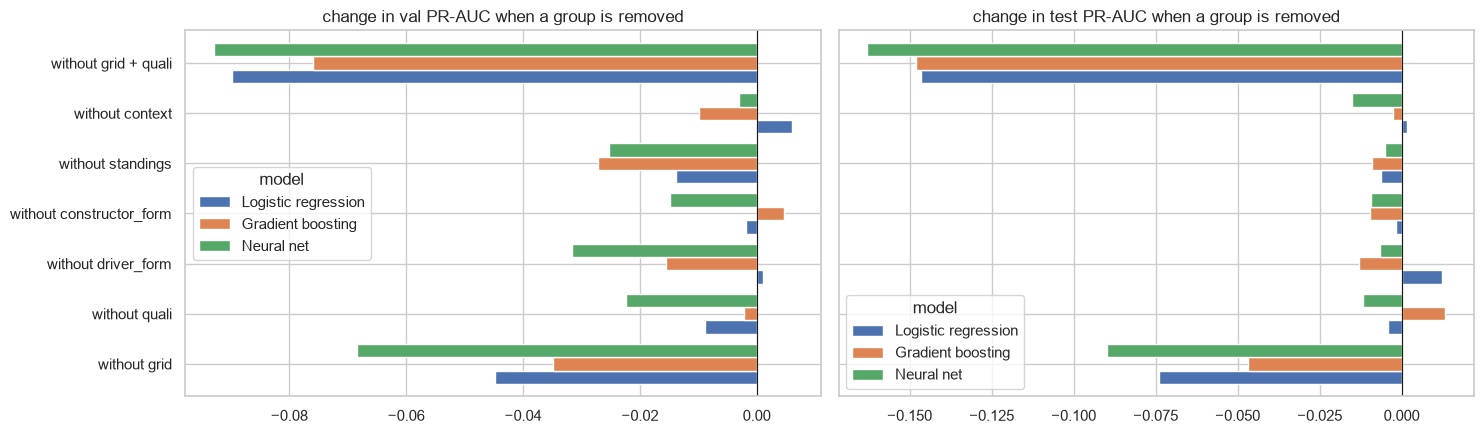

In [50]:
changes = ablation[ablation["scenario"] != "all features"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, col in zip(axes, ["change in val PR-AUC", "change in test PR-AUC"]):
    changes.pivot_table(index="scenario", columns="model", values=col, sort=False).plot.barh(ax=ax, width=0.8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(col + " when a group is removed")
    ax.set_ylabel("")
save("22_ablation")

**What the ablation shows.** (Seed noise for the neural net: test PR-AUC 0.697 +/- 0.007, so changes below about 0.015 are hard to tell apart from noise.)

* **Starting order is the one essential block.** Removing grid and qualifying together costs 0.076-0.093 validation PR-AUC and 0.147-0.163 test PR-AUC for all three models. Removing only the grid group already costs 0.035-0.068 on validation and 0.047-0.090 on test.
* **Qualifying on its own adds little once the grid is there** (validation -0.002 to -0.022, test between -0.012 and +0.013): the grid slot already contains most of what qualifying says.
* **Standings are a small but consistent help**: validation drops by 0.014-0.027 and test by 0.005-0.009 for every model when they are removed.
* **Driver form** matters for the two non-linear models on validation (-0.016 and -0.032) but not for logistic regression. **Constructor form and context** stay within about +/-0.015 with mixed signs; they are second-order once grid and standings are known.

This is the same picture as the feature-selection trials before training: grid first, standings second, the rest fine-tuning.

## 12. Explainability

* **Global:** permutation importance (how much test PR-AUC drops when one feature is shuffled) for the primary model (gradient boosting) and, as a point of comparison, the tuned logistic regression. SHAP for the gradient-boosting model with the exact `TreeExplainer`; its values are in log-odds of a podium.
* **Local:** for two test rows (a typical podium and the biggest surprise podium) we show a SHAP waterfall and a LIME explanation of the same model.

> **These explanations are not causal.** They describe what the fitted model relies on to make its predictions, not what causes a podium. A feature can matter because it stands in for something else (constructor form for car pace), because it is correlated with other features, or because of patterns that only hold in the training eras. Changing a driver's grid slot in the model's input is not the same as that driver starting further up in real life.

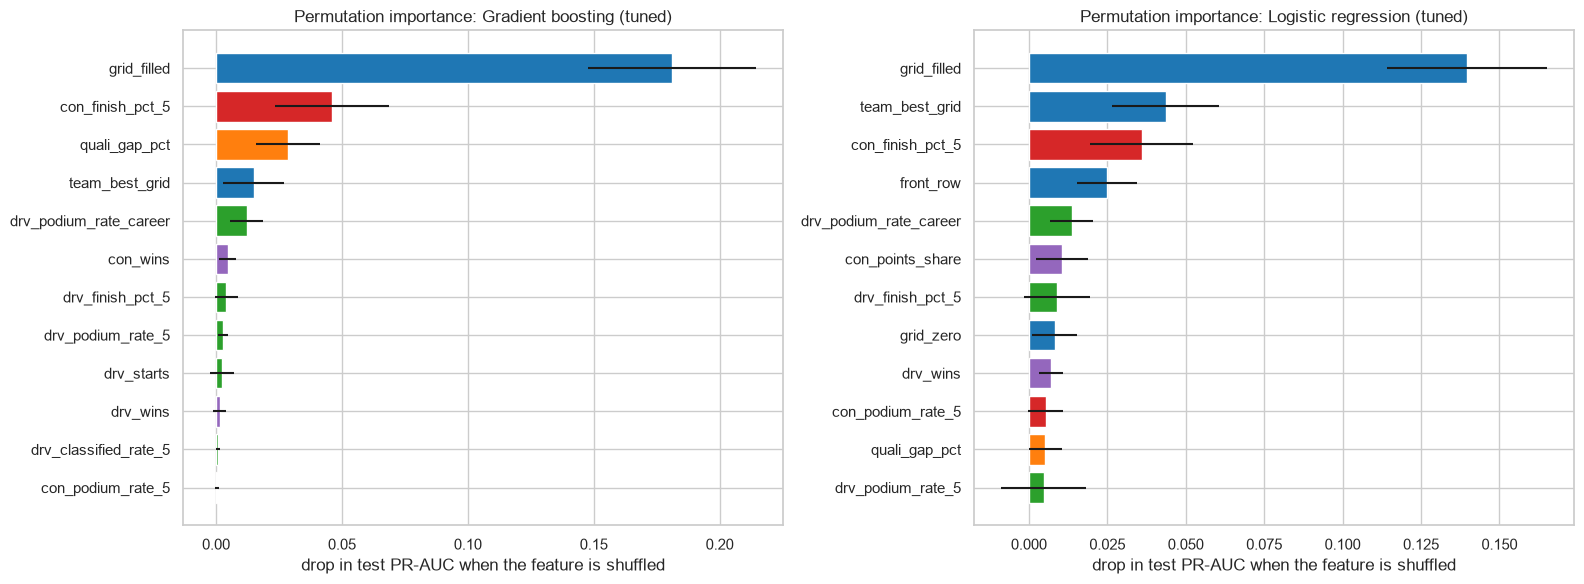

,Gradient boosting (tuned),Logistic regression (tuned)
feature,,
grid_filled,0.1810,0.1396
con_finish_pct_5,0.0461,0.0359
quali_gap_pct,0.0286,0.0052
team_best_grid,0.0150,0.0436
drv_podium_rate_career,0.0121,0.0137
con_wins,0.0047,0.0002
drv_finish_pct_5,0.0041,0.0089
drv_podium_rate_5,0.0027,0.0047
drv_starts,0.0024,0.0008


In [51]:
def perm_importance(pipe):
    result = permutation_importance(pipe, X["test"], y["test"], scoring="average_precision",
                                    n_repeats=10, random_state=SEED)
    return pd.DataFrame({"feature": FEATURES, "importance": result.importances_mean, "std": result.importances_std},
                        ).sort_values("importance", ascending=False)


# the primary model, and the tuned logistic regression as a simple point of comparison
explained = list(dict.fromkeys([PRIMARY, "Logistic regression (tuned)"]))
importances = {name: perm_importance(fitted[name]["pipe"]) for name in explained}

fig, axes = plt.subplots(1, len(explained), figsize=(8 * len(explained), 6))
for ax, (name, imp) in zip(np.atleast_1d(axes), importances.items()):
    top = imp.head(12).iloc[::-1]
    ax.barh(top["feature"], top["importance"], xerr=top["std"], color=top["feature"].map(GROUP_OF).map(colors))
    ax.set_xlabel("drop in test PR-AUC when the feature is shuffled")
    ax.set_title(f"Permutation importance: {name}")
save("23_permutation_importance")
pd.concat({name: imp.set_index("feature")["importance"] for name, imp in importances.items()}, axis=1).round(4).head(12)

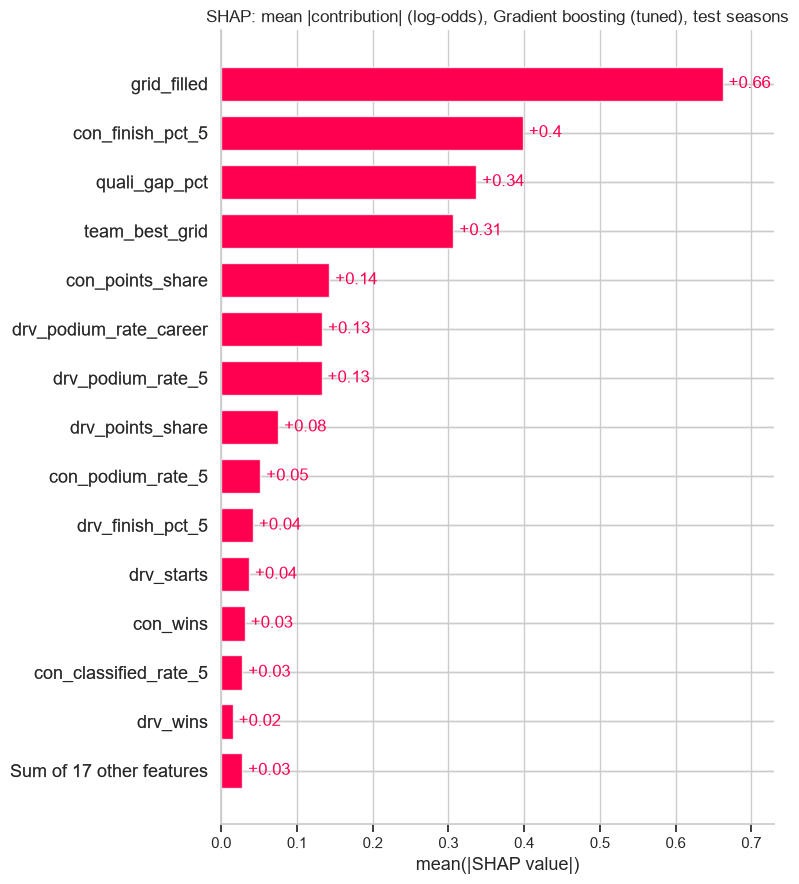

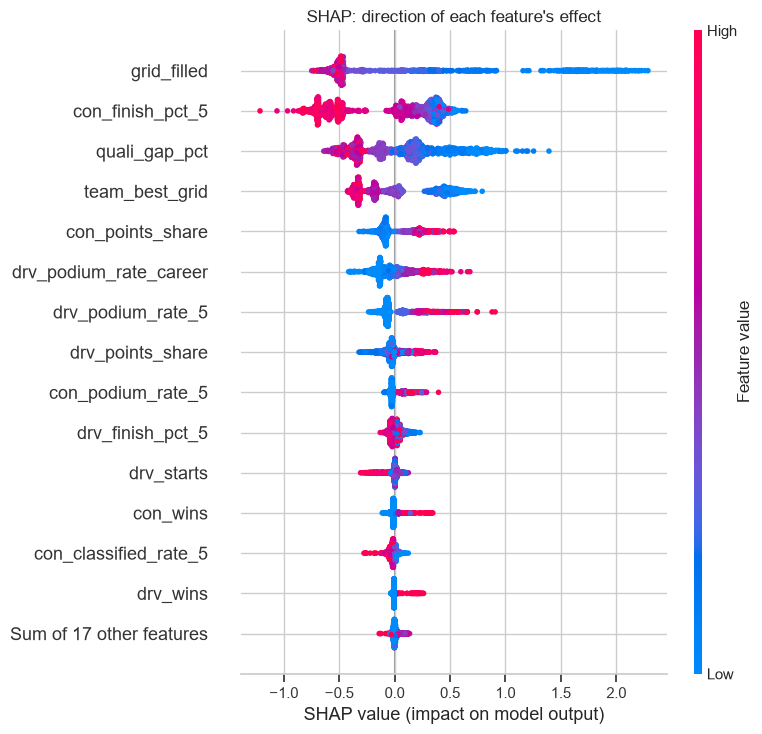

In [52]:
# SHAP for the gradient-boosting model (exact TreeExplainer). Values are in log-odds of a podium.
SHAP_NAME = "Gradient boosting (tuned)"
gb_pipe = fitted[SHAP_NAME]["pipe"]
explainer = shap.TreeExplainer(gb_pipe[-1])
shap_values = explainer(gb_pipe[:-1].transform(X["test"]))
shap_values.feature_names = list(gb_pipe[:-1].get_feature_names_out())
shap_values.data = gb_pipe[:1].transform(X["test"])                           # show imputed but unscaled values

shap.plots.bar(shap_values, max_display=15, show=False)
plt.title(f"SHAP: mean |contribution| (log-odds), {SHAP_NAME}, test seasons")
save("24_shap_bar")
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP: direction of each feature's effect")
save("25_shap_beeswarm")

In [53]:
gb_probs, gb_threshold = fitted[SHAP_NAME]["probs"]["test"], fitted[SHAP_NAME]["threshold"]
test_rows = parts["test"].reset_index(drop=True).assign(p=gb_probs)
hits = test_rows[(test_rows["podium"] == 1) & (test_rows["p"] >= gb_threshold)]
cases = {
    "typical podium": (hits["p"] - hits["p"].median()).abs().idxmin(),               # a normal, correctly called podium
    "surprise podium": test_rows.loc[test_rows["podium"] == 1, "p"].idxmin(),       # the podium the model saw least coming
}
test_rows.loc[list(cases.values()), ["race_name", "year", "forename", "surname", "constructor", "grid", "p", "podium"]].round(3)

,race_name,year,forename,surname,constructor,grid,p,podium
1011,Emilia Romagna Grand Prix,2024,Charles,Leclerc,Ferrari,3.0,0.675,1
690,Dutch Grand Prix,2023,Pierre,Gasly,Alpine F1 Team,12.0,0.006,1


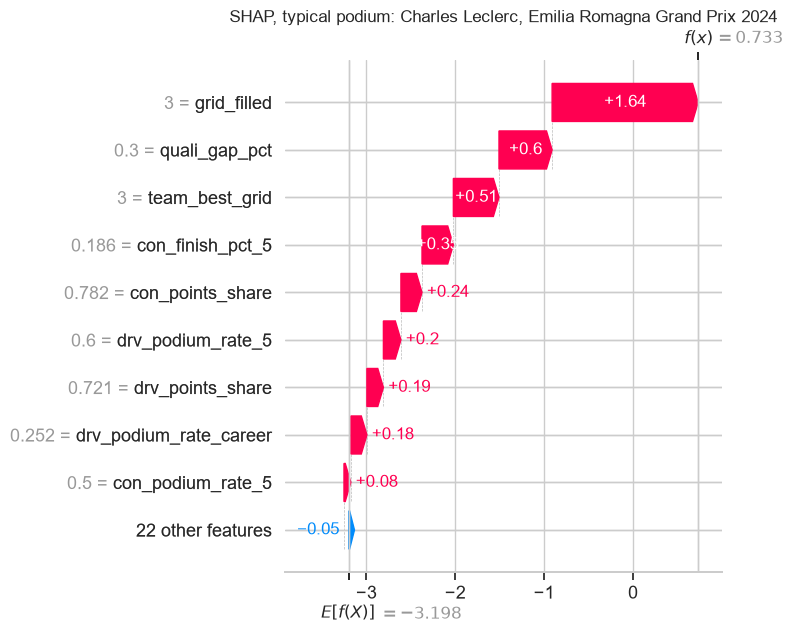

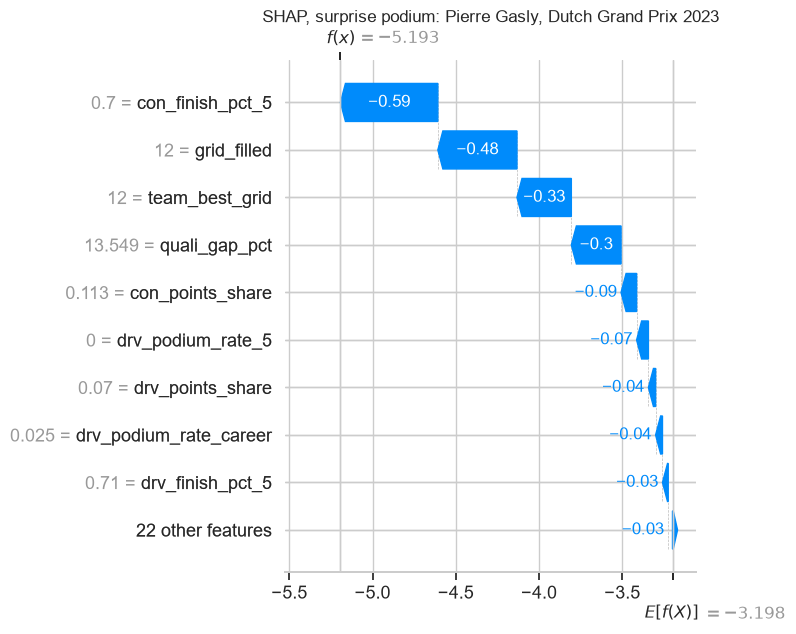

In [54]:
for i, (label, row) in enumerate(cases.items()):
    who = test_rows.loc[row]
    shap.plots.waterfall(shap_values[row], max_display=10, show=False)
    plt.title(f"SHAP, {label}: {who['forename']} {who['surname']}, {who['race_name']} {who['year']}")
    save(f"26_shap_waterfall_{i + 1}")

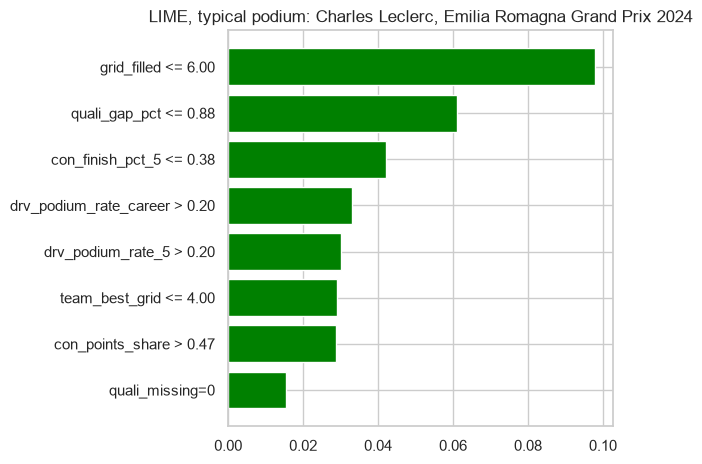

typical podium [('grid_filled <= 6.00', 0.098), ('quali_gap_pct <= 0.88', 0.061), ('con_finish_pct_5 <= 0.38', 0.042), ('drv_podium_rate_career > 0.20', 0.033), ('drv_podium_rate_5 > 0.20', 0.03)]


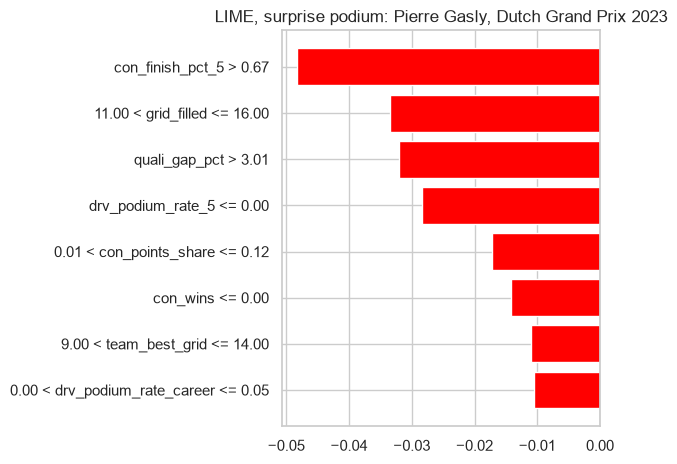

surprise podium [('con_finish_pct_5 > 0.67', -0.048), ('11.00 < grid_filled <= 16.00', -0.034), ('quali_gap_pct > 3.01', -0.032), ('drv_podium_rate_5 <= 0.00', -0.028), ('0.01 < con_points_share <= 0.12', -0.017)]


In [55]:
train_filled = X["train"].fillna(X["train"].median())
lime_explainer = LimeTabularExplainer(
    train_filled.values, feature_names=FEATURES, class_names=["no podium", "podium"], mode="classification",
    categorical_features=[FEATURES.index(f) for f in ["grid_zero", "front_row", "quali_missing"]], random_state=SEED)


def gb_predict(rows):
    return gb_pipe.predict_proba(pd.DataFrame(rows, columns=FEATURES))


for i, (label, row) in enumerate(cases.items()):
    who = test_rows.loc[row]
    values = X["test"].reset_index(drop=True).loc[row].fillna(X["train"].median())
    explanation = lime_explainer.explain_instance(values.values, gb_predict, num_features=8, num_samples=3000)
    explanation.as_pyplot_figure()
    plt.title(f"LIME, {label}: {who['forename']} {who['surname']}, {who['race_name']} {who['year']}")
    save(f"27_lime_{i + 1}")
    print(label, [(rule, round(weight, 3)) for rule, weight in explanation.as_list()[:5]])

**Global explanations.**

* **The grid slot dominates.** For the gradient-boosting model, shuffling `grid_filled` costs 0.181 test PR-AUC, twice as much as the next three features together, and it has by far the largest mean |SHAP| (0.66 log-odds).
* **Then team strength and pace.** Both methods agree on the next three: the team's recent finishing positions (`con_finish_pct_5`, SHAP 0.40, permutation 0.046), the gap to pole (`quali_gap_pct`, 0.34 / 0.029) and the team's best grid slot (`team_best_grid`, 0.31 / 0.015). Constructor points share and the driver's podium rates follow in SHAP (0.13-0.14).
* **The directions make sense** (beeswarm): a low grid number, a small gap to pole, good recent team results and a high points share push the prediction up; a weak team record pushes it down strongly.
* **SHAP vs permutation.** Some standings and form features get SHAP weight but almost no permutation importance (e.g. `con_points_share`). These features are correlated with each other, so when one is shuffled the model still finds the information in the others. The ablation (Section 11) shows the same: removing one of these groups costs little.
* **The logistic regression** relies on the same top features in a slightly different mix: the grid slot first (0.140), then the team's best grid slot (0.044) and recent team results (0.036), and much less on the gap to pole (0.005).

**Local explanations.**

* **Typical podium: Charles Leclerc, Emilia Romagna GP 2024** (started P3, finished on the podium, predicted probability 0.675). SHAP starts from the model's average output (-3.20 log-odds) and the grid slot alone adds +1.64. A tiny gap to pole (0.3%) adds +0.60, the team's best grid slot (P3) +0.51, and good team form and points share add the rest. LIME's strongest rules say the same: `grid_filled <= 6`, `quali_gap_pct <= 0.88`, `con_finish_pct_5 <= 0.38` and a career podium rate above 0.20.
* **Surprise podium: Pierre Gasly, Dutch GP 2023** (started P12, finished P3, predicted probability 0.006). Every important feature pushes down: the team's weak recent results (`con_finish_pct_5` = 0.70, -0.59), the midfield grid slot (-0.48), the team's best slot (-0.33) and a 13.5% gap to pole (-0.30), which is unusually large because Gasly's best lap came from an earlier, slower session than the pole lap. LIME gives the same picture. The podium came from what happened in a rain-hit race, which is exactly the kind of information the model cannot have before the start.

## 13. Inference function

`predict_podium(record)` takes a dictionary with the pre-race features of one driver in one race. Any feature can be missing: it is imputed with the training median (plus its missing indicator), exactly as during training. It returns the podium probability, the yes/no decision at the validation-chosen threshold, and which features were missing.

We demonstrate it on a complete record (Charles Leclerc, Monaco 2024), on the same record with the qualifying and driver-form features removed, and on a record that only has a grid slot.

In [56]:
FINAL = fitted[PRIMARY]


def predict_podium(record, pipe=FINAL["pipe"], threshold=FINAL["threshold"]):
    """Podium probability for one driver in one race.

    `record` maps feature names to values known before the start. Missing keys or None
    values are fine: they are imputed with the training medians, exactly as in training."""
    row = pd.DataFrame([{f: record.get(f) for f in FEATURES}], dtype=float)
    probability = float(pipe.predict_proba(row)[0, 1])
    return {"podium_probability": round(probability, 3),
            "predicted_podium": probability >= threshold,
            "missing_features": [f for f in FEATURES if pd.isna(row.at[0, f])]}


race = df[(df["year"] == 2024) & (df["race_name"] == "Monaco Grand Prix") & (df["surname"] == "Leclerc")].iloc[0]
complete = race[FEATURES].to_dict()
partial = {f: v for f, v in complete.items() if GROUP_OF[f] not in ("quali", "driver_form")}   # no qualifying, no form
grid_only = {"grid_filled": 3, "field_size": 20}

for name, record in [("complete record", complete), ("partially missing (no qualifying, no driver form)", partial),
                     ("only grid slot and field size", grid_only)]:
    out = predict_podium(record)
    print(f"{name:52s} p = {out['podium_probability']:.3f}  podium = {out['predicted_podium']}  "
          f"missing = {len(out['missing_features'])}")

# the function must give the same answer as the pipeline applied to the stored row
assert np.isclose(predict_podium(complete)["podium_probability"],
                  FINAL["pipe"].predict_proba(race[FEATURES].to_frame().T.astype(float))[0, 1], atol=1e-3)
print(f"actual result: {race['forename']} {race['surname']} finished P{int(race['positionOrder'])}")

complete record                                      p = 0.813  podium = True  missing = 0
partially missing (no qualifying, no driver form)    p = 0.557  podium = True  missing = 8
only grid slot and field size                        p = 0.091  podium = False  missing = 19
actual result: Charles Leclerc finished P1


**Results.** With the complete record the model gives Leclerc a 0.813 podium probability (Leclerc won the race). Without the qualifying and driver-form features (8 values missing and imputed) the probability drops to 0.557, but the answer is still "podium". With only a grid slot of 3 and a field of 20 (19 values missing) it falls to 0.091: everything else is filled with training medians, which describe a midfield driver in a midfield car, so a P3 start alone is not enough to convince the model. The function never fails on missing data, but the less it is told, the closer its answer gets to "an average driver".

## 14. Known limitations

* **Qualifying-coverage drift.** `qualifying.csv` starts in 1994 and covers every race only from 2003, so 58% of the modelling rows have no qualifying data. Those values are imputed and flagged, and even where they exist they mean slightly different things across formats (single session in the 1990s, Q1/Q2/Q3 knockout since 2006).
* **Era sensitivity.** F1 changed a lot over 75 years, and older seasons are harder to rank (training PR-AUC 0.766 for 2003-2013 against 0.828 for 2014-2019). That is part of why validation picked a 2003-2019 training window, so the model has never seen racing before 2003. The test seasons are a new regulation era, and team-form features need a few races to catch up after a reset like 2022.
* **Small evaluation sets.** Validation has 39 races (117 podiums) and test 68 races (204 podiums). Differences of about 0.01-0.02 PR-AUC between models are within the noise we measured by changing the random seed.
* **Validation is used several times** (hyperparameters, threshold, training window), so validation scores are a little optimistic. The test seasons were only used for the final report.
* **Team renames** (Toro Rosso -> AlphaTauri -> RB, Renault -> Alpine, ...) get a new `constructorId`, which resets the constructor-form features.
* **Hand-made mappings**: nationality -> country (Q2), status -> mechanical failure (Q3), and the shared-drive rule. They are written out in full above, but someone else could reasonably draw the lines differently.
* **Missing information.** Weather, tyre strategy, safety cars, upgrades and first-lap incidents are not in the data. They explain most "surprise" podiums, like Gasly at Zandvoort 2023 in Section 12.
* **Cutoff edge case.** We treat the final grid as known before the start, including late pit-lane starts.
* **Explanations are associations, not causes** (Section 12).

In [57]:
Path("outputs").mkdir(exist_ok=True)
info = ["raceId", "driverId", "year", "round", "race_name", "forename", "surname", "constructor", "split"]
df[info + FEATURES + ["podium"]].to_csv("outputs/modeling_table.csv", index=False)
comparison.to_csv("outputs/model_comparison.csv")
ablation.to_csv("outputs/ablation_results.csv", index=False)
experiments.to_csv("outputs/preprocessing_experiments.csv")
print(sorted(p.name for p in Path("outputs").iterdir()), len(list(FIG_DIR.glob("*.png"))), "figures")

['ablation_results.csv', 'figures', 'model_comparison.csv', 'modeling_table.csv', 'preprocessing_experiments.csv'] 29 figures
